# Обзор бизнес-показателей маркетплейса

В проекте — быстрорастущий маркетплейс, который уже занял свою нишу и приносит прибыль. Раньше команда принимала решения на основе отчётов в Excel, бухгалтерских сводок и интуиции. Однако с ростом бизнеса этого стало недостаточно: потребовались системный взгляд на продукт, продуктовые данные и аналитика, которая помогает не только описывать текущую ситуацию, но и находить точки роста.

Перед нами стоит задача оценить, как чувствует себя продукт: кто приходит на маркетплейс, кто остаётся и возвращается, кто совершает покупки, а кто уходит. Также важно понять, за счёт каких каналов привлечения держится рост, какие категории товаров и сегменты пользователей приносят больше ценности, а где бизнес теряет деньги или упускает потенциал.

В распоряжении есть данные о пользователях, их событиях в продукте, заказах и расходах на маркетинговые кампании за 2024 год. На их основе необходимо провести первичный обзор ключевых продуктовых метрик, оценить монетизацию и юнит-экономику, выявить закономерности и аномалии, а затем сформулировать гипотезы для развития продукта.

## Анализ построен в несколько этапов:

- обзор динамики ключевых метрик: выручки, активной аудитории, удержания, среднего чека и конверсии в заказ;
- оценка монетизации и эффективности привлечения пользователей: ARPU, AOV, CAC, ROI и срока окупаемости;
- сегментация пользователей и поиск инсайтов по каналам привлечения, регионам, устройствам, категориям товаров и этапам воронки;
- формулирование гипотез и подготовка рекомендаций для дальнейшего развития продукта.

## Цель проекта:
    Собрать целостную картину состояния маркетплейса, определить сильные стороны и проблемные зоны, а также предложить обоснованные направления для роста выручки и улучшения продуктовой экономики.

## Описание данных

### Таблица `Users`

| Поле              | Описание                                       |
|-------------------|------------------------------------------------|
| `user_id`         | Уникальный идентификатор пользователя.         |
| `registration_date` | Дата регистрации пользователя.                |
| `age`             | Возраст пользователя.                          |
| `gender`          | Пол.                                |
| `region`          | Регион.                                        |
| `acq_channel`     | Канал привлечения.                             |
| `buyer_segment`   | Сегмент покупателя.                            |
| `cohort_week`     | Неделя привлечения.|
| `cohort_month`    | Месяц привлечения. |

---

### Таблица `Events`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `event_id`    | Уникальный идентификатор события.                                        |
| `user_id`     | Идентификатор пользователя.                                              |
| `event_date`  | Дата события.                                                            |
| `event_type`  | Тип события.   |
| `os`          | Операционная система.               |
| `device`      | Тип устройства.                                |
| `product_name`| Наименование товара, к которому относится событие (если применимо).      |
| `event_week`  | Неделя события.                                          |
| `event_month` | Месяц события .                                           |

---

### Таблица `Orders`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `order_id`    | Уникальный идентификатор заказа.                                         |
| `user_id`     | Идентификатор пользователя, который сделал заказ |
| `order_date`  | Дата и время оформления заказа.                                          |
| `product_name`| Наименование товара.                                                     |
| `quantity`    | Количество единиц товара в заказе.                                       |
| `unit_price`  | Цена за одну единицу товара.                                             |
| `total_price` | Итоговая сумма заказа.                                                   |
| `category_name` | Наименование категории товара.                                         |
| `order_week`  | Неделя заказа.                                           |
| `order_month` | Месяц заказа.                                            |


### Таблица `Campaign_costs`

| Поле         | Описание                                                                 |
|--------------|--------------------------------------------------------------------------|
| `acq_channel`| Канал привлечения.  |
| `spend_month`| Месяц, в который был потрачен бюджет (отражает период, в котором были привлечены пользователи)                      |
| `budget`     | Маркетинговый бюджет (в денежном выражении), потраченный на данный канал в указанном месяце.                           |



## Описание событий

| Событие             | Описание                                                                                  |
|---------------------|-------------------------------------------------------------------------------------------|
| `page_view`         | Открытие любой страницы сайта или приложения пользователем.                                |
| `product_view`      | Просмотр страницы конкретного товара.                                                     |
| `product_click`     | Клик по товару (например, из списка товаров или на баннере).                              |
| `add_to_cart`       | Добавление товара в корзину.                                                              |
| `remove_from_cart`  | Удаление товара из корзины.                                                               |
| `search`            | Выполнение поиска по сайту или приложению.                                                |
| `filter_apply`      | Применение фильтра (например, по цене, бренду, категории).                                |
| `checkout_start`    | Начало оформления заказа (переход к оформлению корзины).                                  |
| `checkout_complete` | Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты).                                          |
| `user_login`        | Вход пользователя в личный кабинет или аккаунт.                                           |
| `user_logout`       | Выход пользователя из аккаунта.                                                           |
| `wishlist_add`      | Добавление товара в список желаемого (wishlist).                                          |
| `category_view`     | Просмотр страницы категории товаров.                                                      |
| `banner_click`      | Клик по рекламному баннеру на сайте или в приложении.                                     |
| `promo_view`        | Просмотр промо-акции или специального предложения.                                        |


## Выручка маркетплейса = 5% от total_price

## План проекта:
1. Предобработка и подготовка данных.
2. Обзор ключевых метрик.
3. Оценка монетизации и юнит-экономики.
4. Поиск инсайтов, точек роста и сегментация.
5. Подготовка эксперимента и подведение итогов.

---
## Предобработка и подготовка данных

#### Импортируем необходимые для проекта библиотеки:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest

#### Загружаем данные из `.CSV` в `Dataframe`:

In [2]:
pa_marketplace_orders = pd.read_csv('/datasets/pa_marketplace_orders.csv')
pa_marketplace_campaign_costs = pd.read_csv('/datasets/pa_marketplace_campaign_costs.csv')
pa_marketplace_users = pd.read_csv('/datasets/pa_marketplace_users.csv')
pa_marketplace_events = pd.read_csv('/datasets/pa_marketplace_events.csv')

#### Посмотрим на общую информацию о таблицах, типы данных и наличие пропущенных значений:

##### Создадим функцию для вывода общей информации о датасетах и количестве пропусков и применим ее сначала для датасета `users`:

In [3]:
def show_basic_info(df, name):
    print(f"Общая информация о датасете {name}\n")
    df.info()
    print("\nКоличество пропусков по столбцам:")
    print(df.isna().sum())
    
show_basic_info(pa_marketplace_users, "users")

Общая информация о датасете users

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            44151 non-null  int64 
 1   registration_date  44151 non-null  object
 2   age                44151 non-null  int64 
 3   gender             44151 non-null  object
 4   region             44151 non-null  object
 5   acq_channel        44151 non-null  object
 6   buyer_segment      44151 non-null  object
 7   cohort_week        44151 non-null  object
 8   cohort_month       44151 non-null  object
dtypes: int64(2), object(7)
memory usage: 3.0+ MB

Количество пропусков по столбцам:
user_id              0
registration_date    0
age                  0
gender               0
region               0
acq_channel          0
buyer_segment        0
cohort_week          0
cohort_month         0
dtype: int64


##### Теперь применим для датасета `events`:

In [4]:
show_basic_info(pa_marketplace_events, "events")

Общая информация о датасете events

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785859 entries, 0 to 785858
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   event_id      785859 non-null  int64 
 1   user_id       785859 non-null  int64 
 2   event_date    785859 non-null  object
 3   event_type    785859 non-null  object
 4   os            785859 non-null  object
 5   device        785859 non-null  object
 6   product_name  385740 non-null  object
 7   event_week    785859 non-null  object
 8   event_month   785859 non-null  object
dtypes: int64(2), object(7)
memory usage: 54.0+ MB

Количество пропусков по столбцам:
event_id             0
user_id              0
event_date           0
event_type           0
os                   0
device               0
product_name    400119
event_week           0
event_month          0
dtype: int64


##### Теперь применим для датасета `orders`:

In [5]:
show_basic_info(pa_marketplace_orders, "orders")

Общая информация о датасете orders

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31357 entries, 0 to 31356
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       31357 non-null  int64  
 1   user_id        31357 non-null  int64  
 2   order_date     31357 non-null  object 
 3   product_name   31357 non-null  object 
 4   quantity       31357 non-null  int64  
 5   unit_price     31357 non-null  float64
 6   total_price    31357 non-null  float64
 7   category_name  31357 non-null  object 
 8   order_week     31357 non-null  object 
 9   order_month    31357 non-null  object 
dtypes: float64(2), int64(3), object(5)
memory usage: 2.4+ MB

Количество пропусков по столбцам:
order_id         0
user_id          0
order_date       0
product_name     0
quantity         0
unit_price       0
total_price      0
category_name    0
order_week       0
order_month      0
dtype: int64


##### Теперь применим для датасета `campaign_costs`:

In [6]:
show_basic_info(pa_marketplace_campaign_costs, "campaign_costs")

Общая информация о датасете campaign_costs

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   88 non-null     int64  
 1   acq_channel  88 non-null     object 
 2   spend_month  88 non-null     object 
 3   budget       88 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 2.9+ KB

Количество пропусков по столбцам:
Unnamed: 0     0
acq_channel    0
spend_month    0
budget         0
dtype: int64


>Данные загружены, пропусков в ключевых столбцах нет, но нужно провести конвертацию дат в datetime64[ns], удалить `Unnamed: 0` столбец в `campaign_costs` и проверить датасеты на дубликаты.

#### Обработаем пропуски столбца `product_name`  заглушками в таблице `events`:

In [7]:
pa_marketplace_events['product_name'] = pa_marketplace_events['product_name'].fillna('Без товара')
print(f"Осталось пропусков: {pa_marketplace_events['product_name'].isna().sum()}")

Осталось пропусков: 0


#### Удалим технический столбец `Unnamed: 0` из таблицы `campaign_costs`:

In [8]:
pa_marketplace_campaign_costs.drop(columns=['Unnamed: 0'], inplace=True)

In [9]:
users_set = set(pa_marketplace_users['user_id'])
print(
    'Пользователей в events без users:',
    (~pa_marketplace_events['user_id'].isin(users_set)).sum()
)
print(
    'Пользователей в orders без users:',
    (~pa_marketplace_orders['user_id'].isin(users_set)).sum()
)

Пользователей в events без users: 34933
Пользователей в orders без users: 911


#### Даты прочитались как объекты. Преобразуем их в `datetime64[ns]`:

In [10]:
date_cols_users = ['registration_date', 'cohort_week', 'cohort_month']
for col in date_cols_users:
    pa_marketplace_users[col] = pd.to_datetime(pa_marketplace_users[col])
date_cols_events = ['event_date', 'event_week', 'event_month']
for col in date_cols_events:
    pa_marketplace_events[col] = pd.to_datetime(pa_marketplace_events[col])
date_cols_orders = ['order_date', 'order_week', 'order_month']
for col in date_cols_orders:
    pa_marketplace_orders[col] = pd.to_datetime(pa_marketplace_orders[col])
pa_marketplace_campaign_costs['spend_month'] = pd.to_datetime(pa_marketplace_campaign_costs['spend_month'])
#проверка
print(pa_marketplace_users[date_cols_users].dtypes)
print(pa_marketplace_events[date_cols_events].dtypes)
print(pa_marketplace_orders[date_cols_orders].dtypes)
print(pa_marketplace_campaign_costs[['spend_month']].dtypes)

registration_date    datetime64[ns]
cohort_week          datetime64[ns]
cohort_month         datetime64[ns]
dtype: object
event_date     datetime64[ns]
event_week     datetime64[ns]
event_month    datetime64[ns]
dtype: object
order_date     datetime64[ns]
order_week     datetime64[ns]
order_month    datetime64[ns]
dtype: object
spend_month    datetime64[ns]
dtype: object


#### Проверим временной период датасета. Найдем минимальные и максимальные даты в каждой из четырех таблиц:


In [11]:
print(f"Регистрации пользователей: с {pa_marketplace_users['registration_date'].min()} по {pa_marketplace_users['registration_date'].max()}")
print(f"                  События: с {pa_marketplace_events['event_date'].min()} по {pa_marketplace_events['event_date'].max()}")
print(f"                   Заказы: с {pa_marketplace_orders['order_date'].min()} по {pa_marketplace_orders['order_date'].max()}")
print(f"     Расходы на маркетинг: с {pa_marketplace_campaign_costs['spend_month'].min()} по {pa_marketplace_campaign_costs['spend_month'].max()}")

Регистрации пользователей: с 2024-01-01 00:07:00 по 2024-12-31 23:44:00
                  События: с 2024-01-01 00:00:00 по 2024-12-31 00:00:00
                   Заказы: с 2024-01-01 08:03:45 по 2024-12-31 23:00:53
     Расходы на маркетинг: с 2024-01-01 00:00:00 по 2025-01-01 00:00:00


>Данные полностью покрывают 2024 год для `users`, `events` и `orders`. Единственная аномалия - `campaign_costs` доходит до 2025-01-01

In [12]:
late_costs = pa_marketplace_campaign_costs[
    pa_marketplace_campaign_costs['spend_month'] >= '2024-12-01'
].sort_values(by=['spend_month', 'acq_channel'])
display(late_costs)

,acq_channel,spend_month,budget
11,Affiliate,2024-12-01,1.315354e+05
23,Direct,2024-12-01,7.401626e+03
35,Email Marketing,2024-12-01,3.573671e+04
69,SEO,2024-12-01,4.690236e+04
47,Social Media,2024-12-01,1.033104e+05
81,TikTok,2024-12-01,1.533683e+06
82,Affiliate,2025-01-01,1.143237e+05
83,Direct,2025-01-01,6.882217e+03
84,Email Marketing,2025-01-01,2.661749e+04
86,SEO,2025-01-01,4.025770e+04


#### Проверим данные на наличие явных дубликатов строк:

In [13]:
print(f"Users: {pa_marketplace_users.duplicated().sum()}")
print(f"Events: {pa_marketplace_events.duplicated().sum()}")
print(f"Orders: {pa_marketplace_orders.duplicated().sum()}")
print(f"Campaign Costs: {pa_marketplace_campaign_costs.duplicated().sum()}")

Users: 0
Events: 0
Orders: 0
Campaign Costs: 0


#### Изучим уникальные значения в категориальных столбцах, чтобы исключить неявные дубликаты:

In [14]:
print("Уникальные значения Users:")
print("\n - Пол:", pa_marketplace_users['gender'].unique())
print("\n - Регион:", pa_marketplace_users['region'].unique())
print("\n - Канал привлечения:", pa_marketplace_users['acq_channel'].unique())
print("\n - Сегмент покупателя:", pa_marketplace_users['buyer_segment'].unique())
print("\n\nУникальные значения Events:")
print("\n - Тип события:", pa_marketplace_events['event_type'].unique())
print("\n - Платформа:", pa_marketplace_events['os'].unique())
print("\n - Устройство:", pa_marketplace_events['device'].unique())
print("\n\nУникальные значения Orders:")
print("\n - Категория:", pa_marketplace_orders['category_name'].unique())

Уникальные значения Users:

 - Пол: ['M' 'F']

 - Регион: ['Москва' 'Санкт-Петербург' 'Краснодар' 'Другие регионы' 'Нижний Новгород'
 'Екатеринбург' 'Московская область' 'Новосибирск' 'Ростов-на-Дону']

 - Канал привлечения: ['Google Ads' 'Email Marketing' 'Affiliate' 'SEO' 'Social Media' 'TikTok']

 - Сегмент покупателя: ['regular' 'rare' 'one_time' 'medium']


Уникальные значения Events:

 - Тип события: ['page_view' 'product_view' 'product_click' 'add_to_cart' 'checkout_start'
 'checkout_complete' 'user_logout' 'search' 'category_view' 'filter_apply'
 'promo_view' 'wishlist_add' 'user_login' 'banner_click'
 'remove_from_cart']

 - Платформа: ['iOS' 'Windows' 'macOS' 'Android']

 - Устройство: ['mobile' 'desktop' 'tablet']


Уникальные значения Orders:

 - Категория: ['Инструменты и садовый инвентарь' 'Продукты питания' 'Женская одежда'
 'Аксессуары для гаджетов' 'Одежда для спорта' 'Декор и освещение'
 'Детская одежда' 'Детские игрушки' 'Книги и канцтовары'
 'Медицинские товары' 'Ко

#### Выручка бизнеса составляет 5% от `total_price`. Создадим в датасете `Orders` новый столбец `marketplace_revenue` который будет отражать заработок продукта:

In [15]:
pa_marketplace_orders['marketplace_revenue'] = pa_marketplace_orders['total_price'] * 0.05
display(pa_marketplace_orders.head())

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month,marketplace_revenue
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01,553.9130
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01,567.0190
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01,1089.2090
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01,553.9130
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01,104.9795


**Выводы по загрузке данных и предобработке:**
- Данные выгружены корректно.
- Пропуски в столбце `product_name` в таблице `events` заменены заглушками.
- Удалён технический столбец `Unnamed: 0` из таблицы `campaign_costs`.
- Столбцы с датами приведены к типу `datetime`.
- Проведена проверка на явные и неявные дубликаты, данные чистые.
- Создана бизнес-метрика `marketplace_revenue` в таблице заказов. Использование заранее рассчитанной комиссии позволит избежать путаницы в дальнейшем.

---
## 2 Обзор ключевых метрик

- На этом этапе посмотрим на общую динамику ключевых метрик продукта.
- Наша цель здесь - быстро получить целостную картину, не применяя сегментацию и не рассматривая глубокие срезы. Определим, соответствует ли продукт базовым ожиданиям, виден ли рост, есть ли тревожные сигналы.

#### Посчитаем DAU, WAU и MAU как количество уникальных пользователей за день, неделю и месяц соответственно, чтобы проанализировать общую динамику активности аудитории маркетплейса:

In [16]:
dau = pa_marketplace_events.groupby(pa_marketplace_events['event_date'].dt.date)['user_id'].nunique()
wau = pa_marketplace_events.groupby('event_week')['user_id'].nunique()
mau = pa_marketplace_events.groupby('event_month')['user_id'].nunique()

#### Визуализация MAU по месяцам:

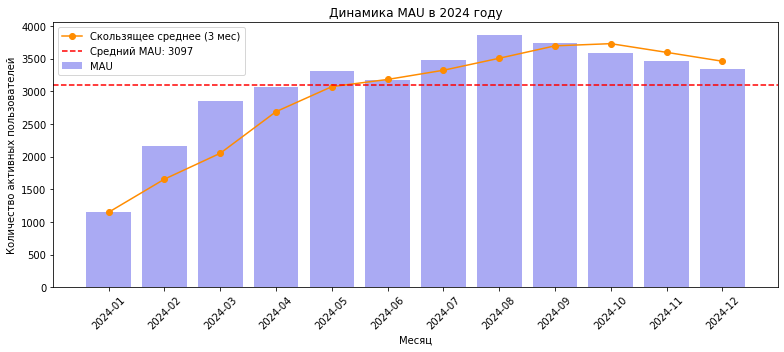

In [17]:
plt.figure(figsize=(11, 5))

sns.barplot(
    x=mau.index.strftime('%Y-%m'),
    y=mau.values,
    color='#9E9EFF',
    label='MAU'
)
plt.plot(
    range(len(mau)),
    mau.rolling(3, min_periods=1).mean().values,
    color='#FF8C00',
    marker='o',
    label='Скользящее среднее (3 мес)'
)
plt.axhline(
    mau.mean(),
    color='#FF0000',
    linestyle='--',
    label=f'Средний MAU: {mau.mean():.0f}'
)
plt.title('Динамика MAU в 2024 году')
plt.xlabel('Месяц')
plt.ylabel('Количество активных пользователей')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

#### Для более детального понимания активности аудитории посмотрим на дневную и недельную динамику уникальных пользователей:

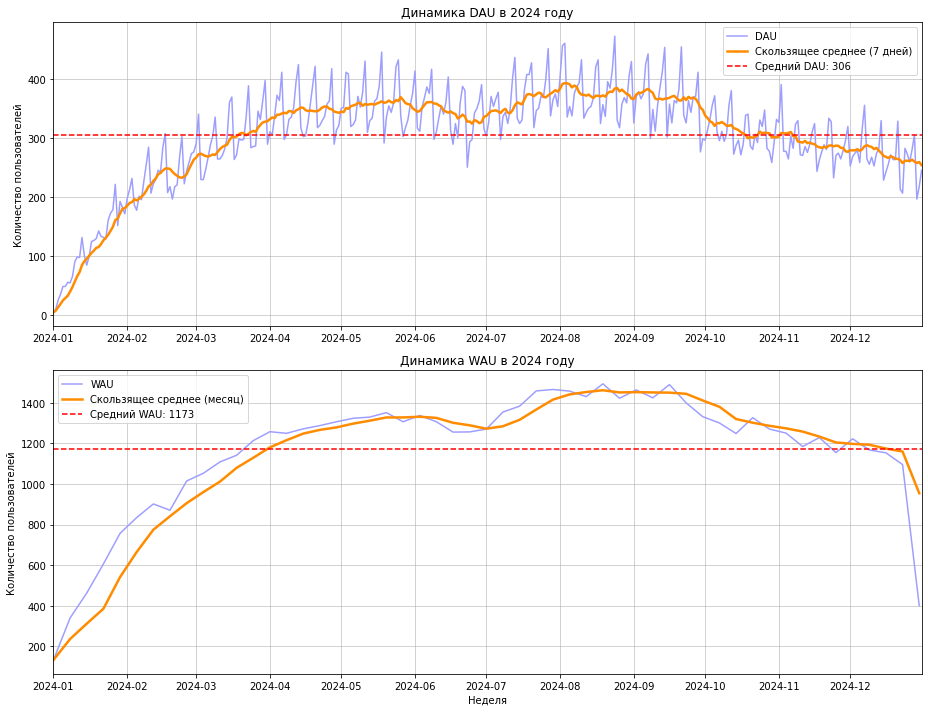

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10))

axes[0].plot(dau, color='#9E9EFF', label='DAU')
axes[0].plot(
    dau.rolling(7, min_periods=1).mean(),
    color='#FF8C00',
    linewidth=2.5,
    label='Скользящее среднее (7 дней)'
)
axes[0].axhline(
    dau.mean(),
    color='red',
    linestyle='--',
    label=f'Средний DAU: {dau.mean():.0f}'
)
axes[0].set(title='Динамика DAU в 2024 году', ylabel='Количество пользователей')
axes[0].grid(alpha=0.7)
axes[0].legend()

axes[1].plot(wau, color='#9E9EFF', label='WAU')
axes[1].plot(
    wau.rolling(4, min_periods=1).mean(),
    color='#FF8C00',
    linewidth=2.5,
    label='Скользящее среднее (месяц)'
)
axes[1].axhline(
    wau.mean(),
    color='red',
    linestyle='--',
    label=f'Средний WAU: {wau.mean():.0f}'
)
axes[1].set(
    title='Динамика WAU в 2024 году',
    xlabel='Неделя',
    ylabel='Количество пользователей'
)
axes[1].grid(alpha=0.7)
axes[1].legend()
axes[0].set_xlim(pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31'))
axes[1].set_xlim(pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31'))
plt.tight_layout()
plt.show()

**Промежуточный вывод:**

- Продукт показывает активный рост с января по август и затем стагнацию с заметным снижением к концу года. MAU, DAU и WAU синхронно идут вниз, что говорит не о разовом скачке, а о системном падении активности и вовлеченности пользователей.

- Для быстрорастущего маркетплейса это тревожный сигнал, так как рост остановился, а в последнем квартале начался отток активной аудитории. Дальше стоит проверить выручку, конверсию и каналы привлечения, чтобы понять, проблема в пользователях или в монетизации.

#### Посмотрим на динамику выручки маркетплейса и средний чек. Также объединим эти данные с MAU, чтобы посчитать ARPU и ARPPU:

In [19]:
monthly_fin = pa_marketplace_orders.groupby('order_month').agg(
    total_sales=('total_price', 'sum'),
    marketplace_revenue=('marketplace_revenue', 'sum'),
    orders_count=('order_id', 'nunique'),
    paying_users=('user_id', 'nunique')
).reset_index()

active_users_monthly = pa_marketplace_events.groupby('event_month')['user_id'].nunique().reset_index()
active_users_monthly.rename(columns={'event_month': 'order_month', 'user_id': 'active_users'}, inplace=True)

monthly_fin = pd.merge(monthly_fin, active_users_monthly, on='order_month', how='left')
monthly_fin['AOV'] = monthly_fin['total_sales'] / monthly_fin['orders_count']
monthly_fin['ARPU'] = monthly_fin['marketplace_revenue'] / monthly_fin['active_users']
monthly_fin['ARPPU'] = monthly_fin['marketplace_revenue'] / monthly_fin['paying_users']
print(f"Средний чек: {monthly_fin['AOV'].mean():.2f}")
print(f"Средний ARPU в месяц: {monthly_fin['ARPU'].mean():.2f}")
print(f"Средний ARPPU в месяц: {monthly_fin['ARPPU'].mean():.2f}")

Средний чек: 13985.56
Средний ARPU в месяц: 593.87
Средний ARPPU в месяц: 1673.43


#### Визуализируем динамику ARPU, ARPPU, AOV:

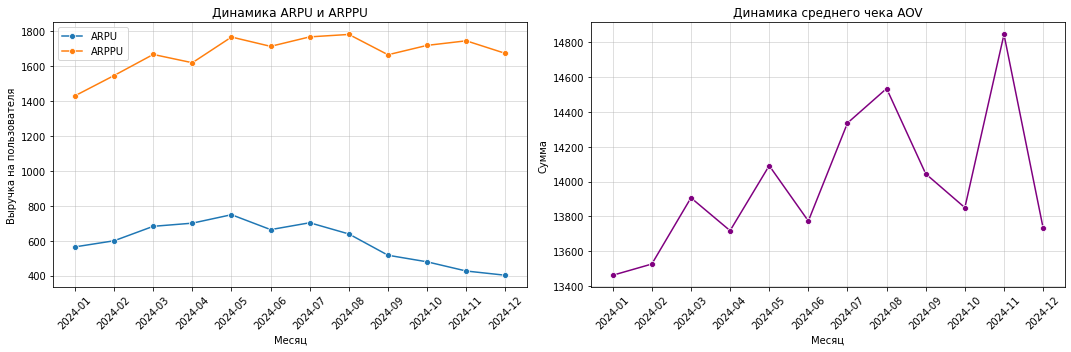

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(data=monthly_fin, x=monthly_fin['order_month'].dt.strftime('%Y-%m'), y='ARPU', marker='o', label='ARPU', ax=axes[0])
sns.lineplot(data=monthly_fin, x=monthly_fin['order_month'].dt.strftime('%Y-%m'), y='ARPPU', marker='o', label='ARPPU', ax=axes[0])
axes[0].set_title('Динамика ARPU и ARPPU')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('Выручка на пользователя')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.5)

sns.lineplot(data=monthly_fin, x=monthly_fin['order_month'].dt.strftime('%Y-%m'), y='AOV', marker='o', color='purple', ax=axes[1])
axes[1].set_title('Динамика среднего чека AOV')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Сумма')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(alpha=0.5)

plt.tight_layout()
plt.show()

**Промежуточный вывод:**

Падение выручки связано с уменьшением доли покупателей среди активных пользователей. Причина снижения конверсии требует дополнительного анализа по шагам воронки, устройствам, каналам и месяцам.

- ARPPU стабилен. Платящие пользователи продолжают покупать примерно на одном уровне 1600–1700. То есть качество самих покупателей не деградировало.

- ARPU рушится. Показатель достигает пика в мае (750), а к декабрю обваливается до минимальных значений года (400), несмотря на снижение базы активных пользователей.

- AOV волатилен, но не критичен. Средний чек колеблется в диапазоне 13,4–14,8 тыс. Резкий всплеск в ноябре 14,8 тыс. объясним сезонными акциями, например 11.11 распродажа, за которым следует жесткое падение в декабре 13,75 тыс, отыгрывающее обратно.

Мы наблюдаем разрыв между ARPU и ARPPU. Раз ARPPU стабилен, а ARPU падает - значит резко снижается доля платящих среди активных пользователей. Пользователи приходят, но перестают доводить до покупки, а привлеченная база не превращается в выручку.

#### Визуализируем динамику выручки маркетплейса по месяцам:

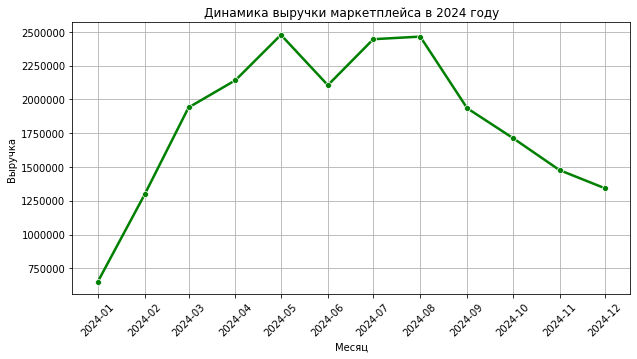

In [21]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_fin, x='order_month', y='marketplace_revenue', marker='o', linewidth=2.5, color='green')
plt.title('Динамика выручки маркетплейса в 2024 году')
plt.xlabel('Месяц')
plt.ylabel('Выручка')
plt.xticks(monthly_fin['order_month'], monthly_fin['order_month'].dt.strftime('%Y-%m'), rotation=45)
plt.grid(True, linestyle='-', alpha=1)
plt.ticklabel_format(axis='y', style='plain')
plt.show()

**Промежуточный вывод:**

- Выручка маркетплейса подтверждает выявленный кризис. Активный рост до мая, стабилизация в июле-августе и резкое, непрерывное падение с сентября по декабрь.

- Это не случайное колебание, а прямое финансовое следствие одновременного падения активной аудитории и конверсии (разрыв ARPU/ARPPU). К декабрю бизнес недополучает более 1 млн. ежемесячно относительно пиковых значений, что делает задачу починки воронки и удержания критически приоритетной для выживания и роста.

#### Оценим, как пользователи двигаются по ключевым этапам - от просмотра страницы до успешного оформления заказа, и найдем общую конверсию в покупку.

In [22]:
funnel_steps = ['page_view', 'product_view', 'add_to_cart', 'checkout_start', 'checkout_complete']
funnel_data = pa_marketplace_events[pa_marketplace_events['event_type'].isin(funnel_steps)]
funnel = funnel_data.groupby('event_type')['user_id'].nunique().reindex(funnel_steps).reset_index()
funnel.columns = ['step', 'users']

fig = go.Figure(go.Funnel(
    y = funnel['step'],
    x = funnel['users'],
    textinfo = "value+percent initial",
    marker = {"color": ["#440154", "#3b528b", "#21918c", "#5ec962", "#fde725"]}
))

fig.update_layout(title_text='Классическая воронка в оформление заказа')
fig.show()

#### В дополнение к общей воронке, посмотрим на конверсию из каждого предыдущего шага в текущий. Это поможет выявить этап, на котором отваливается больше всего пользователей.

In [23]:
fig = go.Figure(go.Funnel(
    y = funnel['step'],
    x = funnel['users'],
    textinfo = "value+percent previous",
    marker = {"color": ["#000004", "#51127c", "#b63679", "#fb8861", "#fcffa4"]}
))

fig.update_layout(title_text='Пошаговая воронка в оформление заказа')
fig.show()

#### Оценим динамику конверсии в заказ по месяцам. Для этого определим количество уникальных пользователей, завершивших оформление заказа в каждом месяце, и разделим его на число всех уникальных активных пользователей за тот же период.

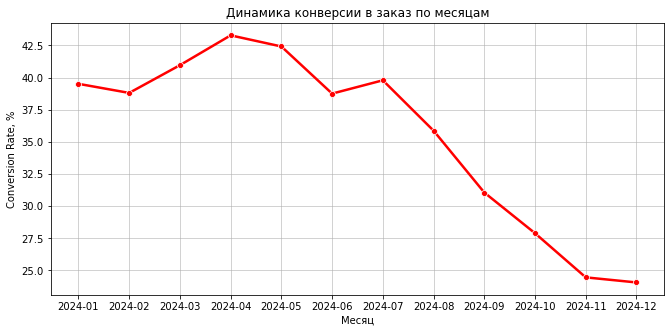

In [24]:
monthly_cr = pd.merge(
    pa_marketplace_orders.groupby('order_month')['user_id'].nunique().reset_index(name='buyers'),
    pa_marketplace_events.groupby('event_month')['user_id'].nunique().reset_index(name='active_users'),
    left_on='order_month',
    right_on='event_month'
)
monthly_cr['cr'] = monthly_cr['buyers'] / monthly_cr['active_users'] * 100

plt.figure(figsize=(11, 5))
sns.lineplot(data=monthly_cr, x=monthly_cr['order_month'].dt.strftime('%Y-%m'), y='cr', marker='o', color='#FF0000', linewidth=2.5)
plt.title('Динамика конверсии в заказ по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Conversion Rate, %')
plt.grid(alpha=0.7)
plt.show()

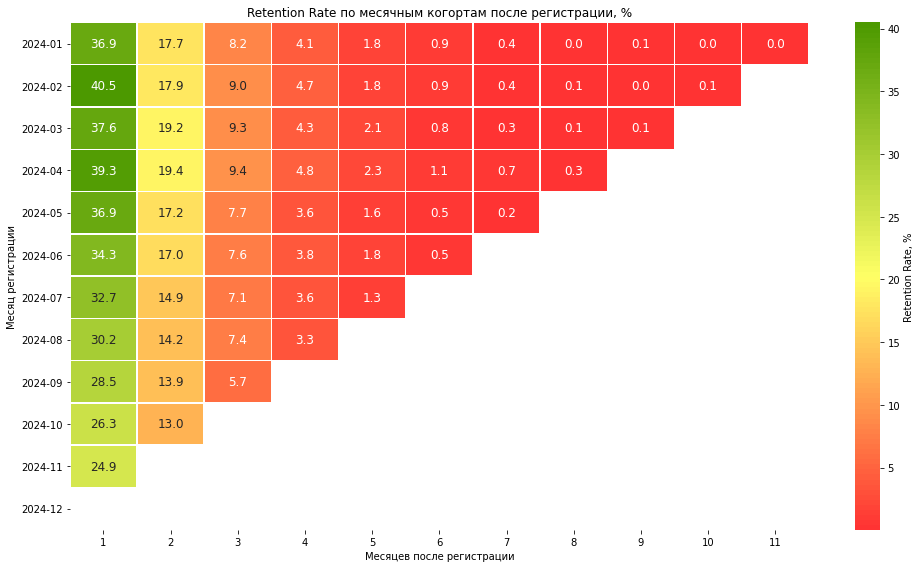

In [25]:
cohort_sizes = (
    pa_marketplace_users
    .groupby('cohort_month')['user_id']
    .nunique()
)
cohorts = (
    pa_marketplace_events[['user_id', 'event_month']]
    .merge(
        pa_marketplace_users[['user_id', 'cohort_month']],
        on='user_id',
        how='inner'
    )
)
cohorts['n_period'] = (
    (cohorts['event_month'].dt.year - cohorts['cohort_month'].dt.year) * 12
    + cohorts['event_month'].dt.month - cohorts['cohort_month'].dt.month
)
#оставим активность начиная со следующего месяца после регистрации
cohorts = cohorts[cohorts['n_period'] > 0]
active_users = cohorts.pivot_table(
    index='cohort_month',
    columns='n_period',
    values='user_id',
    aggfunc='nunique'
)
retention_rate = active_users.div(cohort_sizes, axis=0) * 100
retention_rate.index = retention_rate.index.strftime('%Y-%m')
cmap = mcolors.LinearSegmentedColormap.from_list(
    'red_yellow_green',
    ['#FF3333', '#FFFF66', '#4C9900'],
    N=100
)
plt.figure(figsize=(14, 8))
sns.heatmap(
    retention_rate,
    cmap=cmap,
    annot=True,
    fmt='.1f',
    annot_kws={'size': 12},
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Retention Rate, %'}
)
plt.title('Retention Rate по месячным когортам после регистрации, %')
plt.xlabel('Месяцев после регистрации')
plt.ylabel('Месяц регистрации')
plt.tight_layout()
plt.show()

**Итоговый вывод по блоку "Обзор ключевых метрик":**

Воронка окончательно замыкает всю картину кризиса и точно указывает на локализацию проблемы. Продукт сталкивается с падением активности, падением конверсии в заказ и провальным удержанием поздних когорт.

- **Общая конверсия** от просмотра страницы до успешного оформления заказа составляет **62,9%**, что неплохо для верхних этапов, но имеет два узких места. **Основные потери** происходят на шаге **checkout_start** - потеря **17,8% пользователей, пришедших с корзины** и на шаге **add_to_cart** (**потеря 7,5**) При этом **пользователи, которые дошли до начала оформления, завершают его с высокой вероятностью (82,9% конверсии из шага в шаг)**. Это говорит о проблеме на этапе оплаты и оформления, а не о низком интересе к товару.
- **Динамика конверсии в заказ по месяцам** показывает **устойчивый рост до апреля-мая (пик 42,5%)**, затем **стагнацию до июля (40%)** и последующее непрерывное **обрушение к декабрю (24%)**.
- **Когортный анализ** показывает, что у **поздних когорт удержание заметно хуже по сравнению с когортами первой половины года**. То есть пользователи не только перестали покупать, но и перестали возвращаться.

**Итог** - ARPPU стабилен, покупатели платят, AOV не проваливается, но выручка падает потому, что активная аудитория не конвертируется в покупателей, CR падает, а новые когорты не удерживаются. Снижение выручки на 1 млн. относительно пика это прямое следствие обвала конверсии с сентября и обвала удержания в последних когортах.

### 3 Оценка метрик монетизации и юнит-экономики

Проанализируем монетизацию и определим, сколько зарабатывает продукт и сколько тратит на привлечение.

#### Сначала оставляем только расходы за 2024 год и считаем, сколько пользователей, затрат и выручки приходится на каждый канал привлечения. Затем объединяем эти показатели в одну таблицу для дальнейшего расчёта юнит-экономики:

In [26]:
costs = pa_marketplace_campaign_costs[pa_marketplace_campaign_costs['spend_month'] < '2025-01-01']
users_by_channel = pa_marketplace_users.groupby('acq_channel')['user_id'].nunique()
spend_by_channel = costs.groupby('acq_channel')['budget'].sum()
orders_with_channels = pa_marketplace_orders.merge(
    pa_marketplace_users[['user_id', 'acq_channel']],
    on='user_id',
    how='left'
)
rev_by_channel = orders_with_channels.groupby('acq_channel')['marketplace_revenue'].sum()
unit_eco = pd.DataFrame({
    'Users': users_by_channel,
    'Spend': spend_by_channel,
    'Revenue': rev_by_channel
}).fillna(0)

#### После объединения данных исключаем канал Direct, так как он не является полноценным платным каналом привлечения. Далее считаем CAC, LTV и ROI для каждого канала, чтобы сравнить эффективность привлечения и монетизации.

In [27]:
unit_eco = unit_eco[unit_eco.index != 'Direct']
unit_eco['CAC'] = unit_eco['Spend'] / unit_eco['Users']
unit_eco['LTV'] = unit_eco['Revenue'] / unit_eco['Users']
unit_eco['ROI'] = ((unit_eco['LTV'] - unit_eco['CAC']) / unit_eco['CAC']) * 100
unit_eco = unit_eco.sort_values('ROI', ascending=False)

####  Сравнение CAC и LTV:

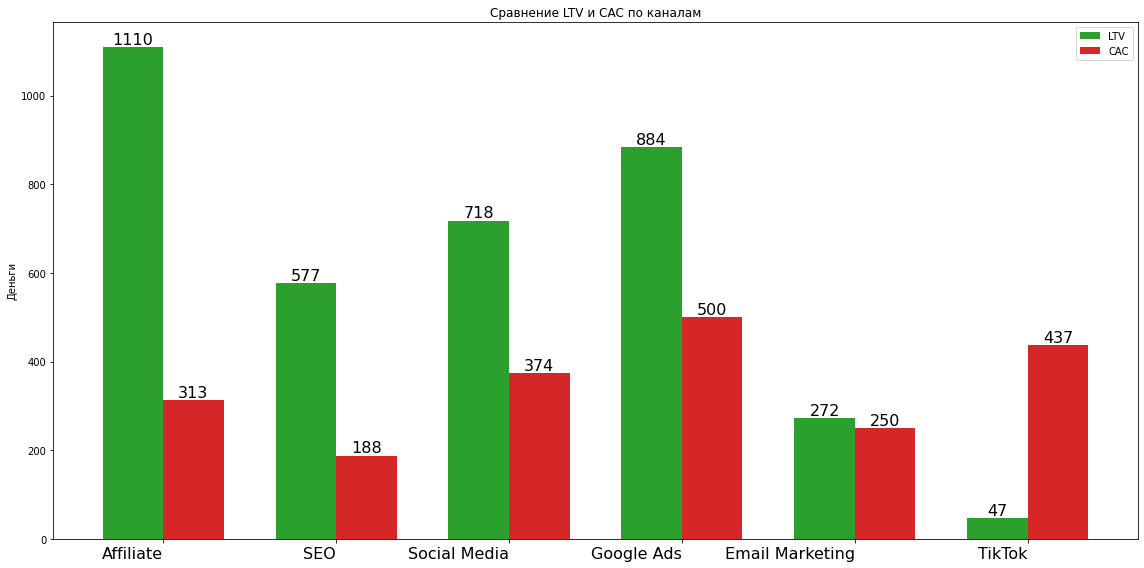

In [28]:
fig, ax = plt.subplots(figsize=(16, 8))
x = np.arange(len(unit_eco.index))
width = 0.35
bars1 = ax.bar(x - width/2, unit_eco['LTV'], width, label='LTV', color='#2ca02c')
bars2 = ax.bar(x + width/2, unit_eco['CAC'], width, label='CAC', color='#d62728')
ax.set_ylabel('Деньги')
ax.set_title('Сравнение LTV и CAC по каналам')
ax.set_xticks(x)
ax.set_xticklabels(unit_eco.index, ha='right', fontsize=16)
ax.legend()

for bar in bars1:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:.0f}',
        ha='center',
        va='bottom',
        fontsize=16
    )
for bar in bars2:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:.0f}',
        ha='center',
        va='bottom',
        fontsize=16
    )
plt.tight_layout()
plt.show()

- Affiliate и SEO показывают отличную экономику. LTV значительно превышает CAC. Это самые маржинальные каналы.
- Social Media и Google Ads также прибыльны, но стоимость привлечения здесь уже существенно выше, что снижает маржу.
- Email Marketing балансирует на грани окупаемости, а TikTok является абсолютно убыточным - тратим 437 на привлечение, а получаем всего 47 дохода с пользователя.

#### Сравним ROI по каналам визуально:

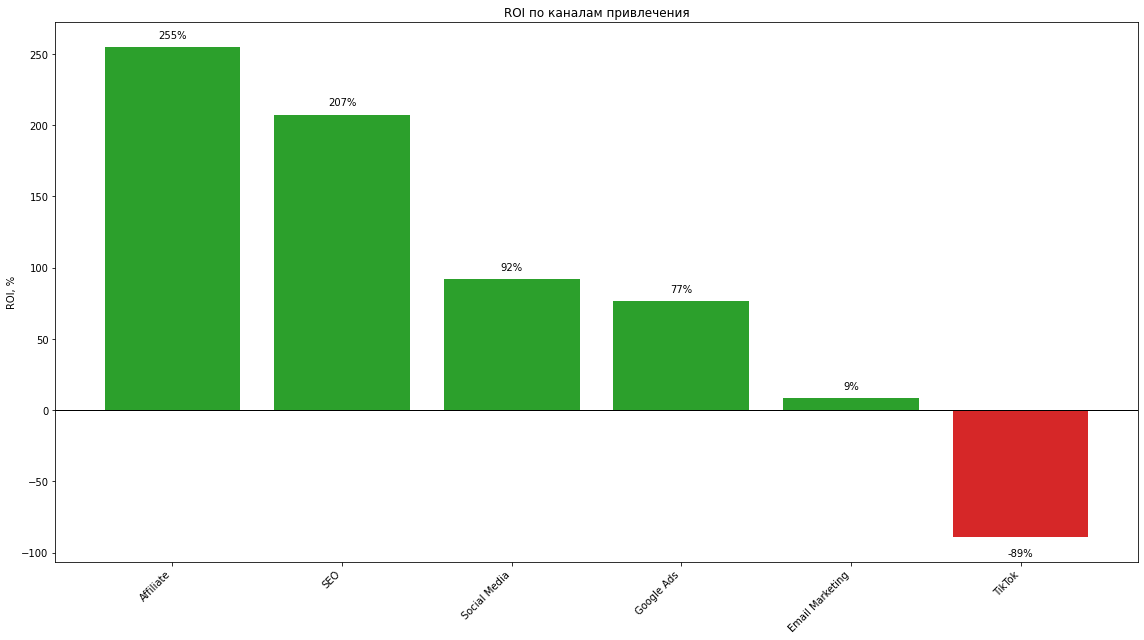

In [29]:
fig, ax = plt.subplots(figsize=(16, 9))
x = np.arange(len(unit_eco.index))
colors = ['#2ca02c' if roi > 0 else '#d62728' for roi in unit_eco['ROI']]
bars = ax.bar(x, unit_eco['ROI'], color=colors)
ax.set_ylabel('ROI, %')
ax.set_title('ROI по каналам привлечения')
ax.set_xticks(x)
ax.set_xticklabels(unit_eco.index, rotation=45, ha='right')
ax.axhline(0, color='black', linewidth=1)

for bar in bars:
    yval = bar.get_height()
    offset = 5 if yval > 0 else -15
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        yval + offset,
        f'{yval:.0f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

- График подтверждает предыдущие выводы. Лучшие показатели у Affiliate (255%) и SEO (207%) каждый вложенный рубль приносит более 2 рублей прибыли.
- Social Media (92%) и Google Ads (77%) работают в плюс, но уже не так эффективно.
- Email Marketing (9%) находится практически в точке безубыточности.
- TikTok (-89%) является каналом, который сжигает бюджет - на каждый вложенный рубль бизнес теряет почти 90 копеек.

#### Подготовим данные о маркетинговых расходах по месяцам:

In [30]:
costs_monthly = (
    pa_marketplace_campaign_costs[pa_marketplace_campaign_costs['spend_month'] < '2025-01-01']
    .groupby('spend_month')['budget']
    .sum()
    .reset_index()
)
cohort_sizes = (
    pa_marketplace_users
    .groupby('cohort_month')['user_id']
    .nunique()
    .reset_index(name='cohort_size')
)
cac_df = pd.merge(cohort_sizes, costs_monthly, left_on='cohort_month', right_on='spend_month', how='inner')
cac_df['cac'] = cac_df['budget'] / cac_df['cohort_size']
display(cac_df.head())

,cohort_month,cohort_size,spend_month,budget,cac
0,2024-01-01,2985,2024-01-01,1.177457e+06,394.457945
1,2024-02-01,2711,2024-02-01,1.061386e+06,391.510856
2,2024-03-01,2965,2024-03-01,1.167680e+06,393.821373
3,2024-04-01,2905,2024-04-01,1.147740e+06,395.091194
4,2024-05-01,3066,2024-05-01,1.225322e+06,399.648493


#### Рассчитаем кумулятивный LTV и ROI с учетом горизонта жизни когорты

In [31]:
orders_users = pd.merge(pa_marketplace_orders, pa_marketplace_users[['user_id', 'cohort_month']], on='user_id', how='left')
orders_users['N_month'] = (orders_users['order_month'].dt.year - orders_users['cohort_month'].dt.year) * 12 + \
                          (orders_users['order_month'].dt.month - orders_users['cohort_month'].dt.month)
revenue_cohorts = orders_users.groupby(['cohort_month', 'N_month'])['marketplace_revenue'].sum().reset_index()

cohort_data = pd.merge(revenue_cohorts, cohort_sizes, on='cohort_month')
cohort_data = pd.merge(cohort_data, cac_df[['cohort_month', 'cac']], on='cohort_month')
cohort_data = cohort_data.sort_values(['cohort_month', 'N_month'])
cohort_data['cum_revenue'] = cohort_data.groupby('cohort_month')['marketplace_revenue'].cumsum()
cohort_data['ltv'] = cohort_data['cum_revenue'] / cohort_data['cohort_size']
cohort_data['roi'] = (cohort_data['ltv'] - cohort_data['cac']) / cohort_data['cac']
display(cohort_data.head())

,cohort_month,N_month,marketplace_revenue,cohort_size,cac,cum_revenue,ltv,roi
0,2024-01-01,0.0,623485.5890,2985,394.457945,6.234856e+05,208.872894,-0.470481
1,2024-01-01,1.0,693054.8455,2985,394.457945,1.316540e+06,441.052072,0.118122
2,2024-01-01,2.0,413166.8270,2985,394.457945,1.729707e+06,579.466419,0.469020
3,2024-01-01,3.0,147712.2805,2985,394.457945,1.877420e+06,628.951270,0.594470
4,2024-01-01,4.0,153252.4020,2985,394.457945,2.030672e+06,680.292109,0.724625


#### Построим линейные графики динамики LTV, CAC и ROI:

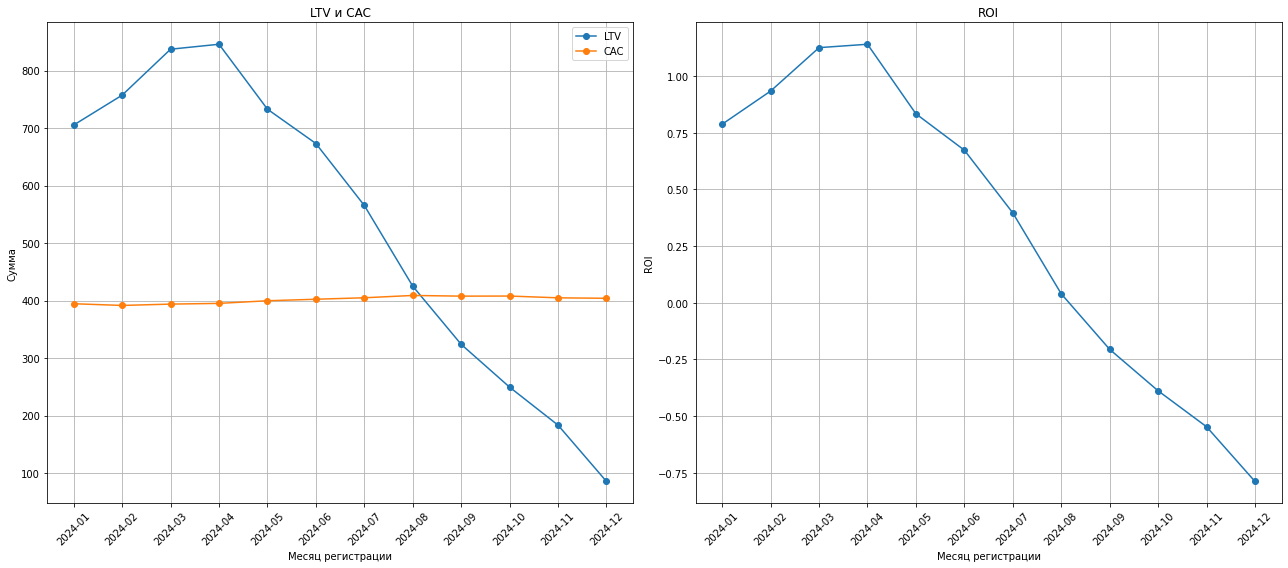

In [32]:
current_metrics = cohort_data.groupby('cohort_month').last().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].plot(current_metrics['cohort_month'].dt.strftime('%Y-%m'), current_metrics['ltv'], marker='o', label='LTV')
axes[0].plot(current_metrics['cohort_month'].dt.strftime('%Y-%m'), current_metrics['cac'], marker='o', label='CAC')
axes[0].set_title('LTV и CAC')
axes[0].set_xlabel('Месяц регистрации')
axes[0].set_ylabel('Сумма')
axes[0].grid(True)
axes[0].legend()
axes[0].tick_params(axis='x', rotation=45)

axes[1].plot(current_metrics['cohort_month'].dt.strftime('%Y-%m'), current_metrics['roi'], marker='o')
axes[1].set_title('ROI')
axes[1].set_xlabel('Месяц регистрации')
axes[1].set_ylabel('ROI')
axes[1].grid(True)
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

#### Построим тепловую карту окупаемости:

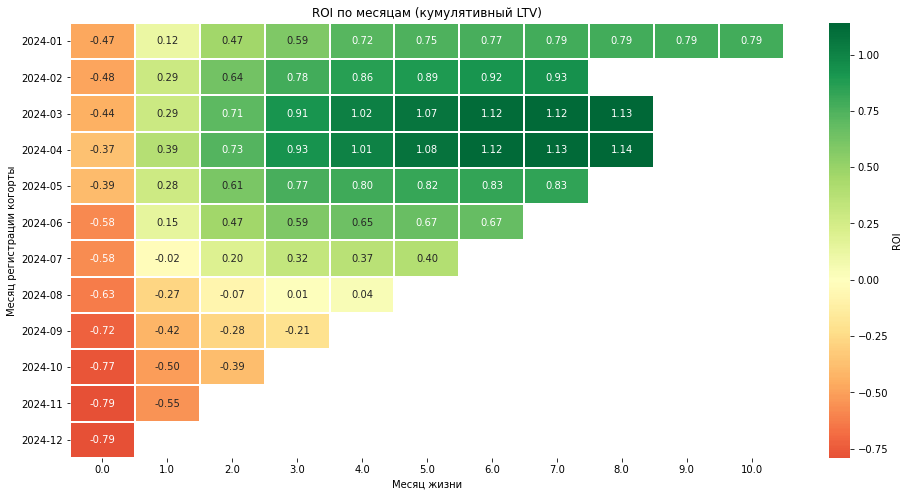

In [33]:
roi_pivot = cohort_data.pivot_table(index='cohort_month', columns='N_month', values='roi')
roi_pivot.index = roi_pivot.index.strftime('%Y-%m')

plt.figure(figsize=(16, 8))
sns.heatmap(
    roi_pivot, 
    annot=True, 
    fmt=".2f", 
    cmap="RdYlGn", 
    center=0,
    linewidths=1,
    cbar_kws={'label': 'ROI'}
)
plt.title('ROI по месяцам (кумулятивный LTV)')
plt.ylabel('Месяц регистрации когорты')
plt.xlabel('Месяц жизни')
plt.show()

#### Визуализируем ROI для каждой месячной когорты. Положительное значение ROI означает, что выручка когорты превысила затраты на её привлечение, отрицательное - что затраты пока не окупились:

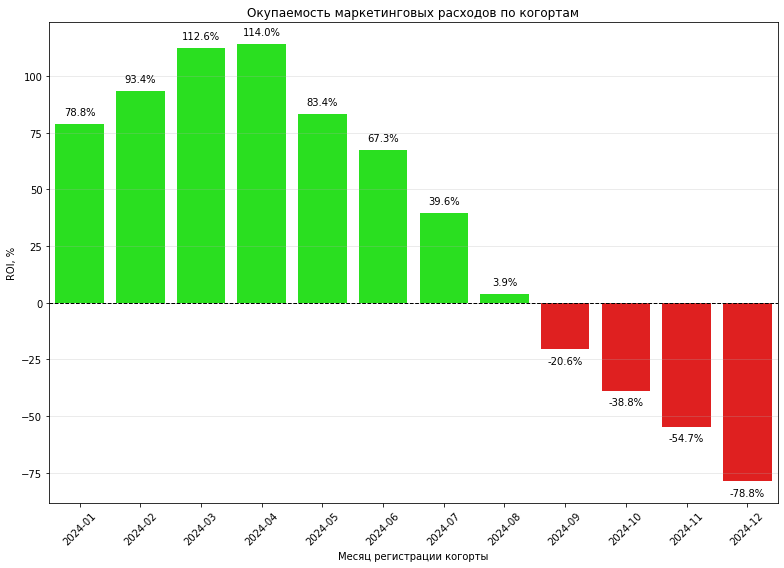

In [34]:
unit_econ = current_metrics.copy()
unit_econ['ROI'] = unit_econ['roi'] * 100

plt.figure(figsize=(11, 8))
colors = unit_econ['ROI'].apply(
    lambda x: '#0EFF00' if x >= 0 else '#FF0000'
).tolist()
ax = sns.barplot(
    data=unit_econ,
    x=unit_econ['cohort_month'].dt.strftime('%Y-%m'),
    y='ROI',
    palette=colors
)
plt.title('Окупаемость маркетинговых расходов по когортам')
plt.xlabel('Месяц регистрации когорты')
plt.ylabel('ROI, %')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

for p in ax.patches:
    y = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2,
        y + (3 if y >= 0 else -3),
        f'{y:.1f}%',
        ha='center',
        va='bottom' if y >= 0 else 'top'
    )
plt.tight_layout()
plt.show()

**Итоговый вывод по блоку "Оценка метрик монетизации и юнит-экономики":**

Мы привлекаем пользователей по стабильной цене, но они приносят всё меньше денег. С сентября 2024 года привлеченные пользователи перестали приносить деньги, что привело к глубокой убыточности маркетинга.

- Стоимость привлечения стабильна. С января по декабрь CAC держится в узком коридоре 391–408 рублей. Рекламные площадки не подорожали.
- Выручка на пользователя обвалилась. Если когорты января–апреля приносили 705–845 рублей на человека, то когорты августа–декабря приносят всего 425–85 рублей.
- Пик ROI пришелся на март-апрель (112–114%). Начиная с сентября, каждая новая когорта становится убыточной - сентябрь -21%, октябрь -39%, ноябрь -55%, декабрь -79%. Мы тратим 400 рублей на привлечение человека, который приносит обратно всего 85 рублей.
- Наиболее маржинальные каналы - Affiliate (ROI 255%) и SEO (ROI 207%). Убыточный канал - TikTok (ROI -89%), где на 437 рублей затрат мы получаем лишь 47 рублей выручки.
- Платящие пользователи тратят столько же, но доля покупателей среди активной аудитории резко упала, конверсия обвалилась с 42,5% до 24%. Из-за этого новые когорты не успевают окупить вложенный в них бюджет.

## Выводы по этапам 2 и 3


Продукт находится в системном кризисе, который выражается в одновременном падении активности аудитории, конверсии в заказ и качества привлеченного трафика. При этом продукт не теряет в цене (ARPPU стабилен, AOV не проваливается), он теряет в количестве покупателей и их возвращаемости.

1. Где именно мы теряем пользователей (воронка и конверсия):

- Общая конверсия от просмотра до оформления (62,9%) скрывает критическую проблему на шаге **checkout_start** (теряем 17,8% пришедших с корзины). Это говорит о проблемах на этапе оплаты/оформления, а не об отсутствии интереса к товарам.

- Динамика конверсии по месяцам подтверждает обвал - пик 42,5% (апрель-май), стагнация 40% (июль) и крутое падение до 24% (декабрь).

- Когортный анализ удержания показывает, что поздние когорты имеют удержание ниже ранних. пользователи перестают возвращаться.

2. Юнит-экономика:

- Стоимость привлечения (CAC) стабильна на уровне 400 на пользователя, но выручка с него рухнула с пиковых 845 до 85. Мы не переплачиваем за трафик - мы получаем некачественный трафик.

- До августа включительно маркетинг работал в плюс (максимальный ROI 114% в апреле). Начиная с сентября каждый новый пользователь приносит убыток: ROI сентября -20%, октября -39%, ноября -55%, декабря -79%. Недополучение выручки относительно пика составляет более 1 млн в конце года.

3. Где искать точки роста и точки оттока в каналах:

- Убыточные каналы - TikTok и Email Marketing (ROI 9%, работает вхолостую) - нужно заморозить или переработать.

- Affiliate (ROI 255%) и SEO (ROI 207%) - самые маржинальные каналы. Именно туда необходимо перераспределить бюджет.

- Social Media (92%) и Google Ads (77%) - будет полезно заняться их оптимизацией, возможно, удастся выжать из них больше.

## 4. Поиск инсайтов, точек роста и сегментация


Посмотрим вглубь данных и пройдёмся: 
- по каналам
- сегментам пользователей
- категориям товаров
- регионам
- типам устройств.

Будем искать закономерности, различия, аномалии.

Наша цель здесь - сформировать обоснованные гипотезы:

- какие сегменты работают лучше остальных
- какие сегменты работают хуже остальных
- на каких этапах воронки теряются пользователи
- какие группы можно или нужно масштабировать
- куда стоит инвестировать больше внимания или ресурсов

### Составим портрет аудитории и географии маркетплейса.

#### Для начала выясним, кто же больше тратит мужчины или женщины и разделим клиентов на возрастные группы:
- До 24 лет
- От 25 до 34 лет
- От 35 до 44 лет
- от 45 до 54 лет
- от 55 лет

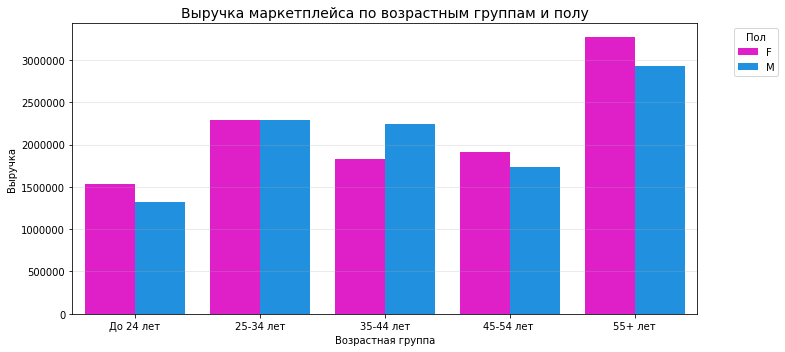

In [35]:
demo_df = pa_marketplace_orders.merge(pa_marketplace_users[['user_id', 'age', 'gender']], on='user_id')
#создадим возрастные корзинки
bins = [0, 24, 34, 44, 54, 1000]
labels = ['До 24 лет', '25-34 лет', '35-44 лет', '45-54 лет ', '55+ лет']
demo_df['age_group'] = pd.cut(demo_df['age'], bins=bins, labels=labels)

demo_revenue = demo_df.groupby(['age_group', 'gender'])['marketplace_revenue'].sum().reset_index()

plt.figure(figsize=(11, 5))
sns.barplot(
    data=demo_revenue, 
    x='age_group', 
    y='marketplace_revenue', 
    hue='gender',
    palette={'M': '#0096FF', 'F': '#FF00E1'}
)
plt.title('Выручка маркетплейса по возрастным группам и полу', fontsize=14)
plt.xlabel('Возрастная группа')
plt.ylabel('Выручка')
plt.grid(axis='y', alpha=0.3)
plt.ticklabel_format(axis='y', style='plain')
plt.legend(title='Пол', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

- Ядро аудитории (Категория 55+): 
    - Самая большая выручка приходится на возрастную группу 55+ лет, причем и мужчины, и женщины тратят здесь больше других групп, но женщины тратят больше. Это ключевой сегмент, который нельзя игнорировать.

- Вторая группа (25-34): 
    - Группа 25-34 года также приносит высокую выручку, распределение между мужчинами и женщинами здесь практически одинаковое.

- Группа (35-44): 
    - В группе 35-44 мужчины тратят заметно больше, чем женщины. Это может указывать на то, что для женщин 35-44 лет продукт или ассортимент недостаточно релевантен.

- Наименьший вклад (До 24): 
    - Аудитория младше 24 лет приносит наименьшую выручку. Это может говорить о том, что эта аудитория просто не является целевой аудиторией маркетплейса.

#### Теперь посмотрим, какие регионы приносят наибольшую выручку маркетплейсу. Для начала визуализируем суммарную выручку по каждому региону и посмотрим на лидеров:

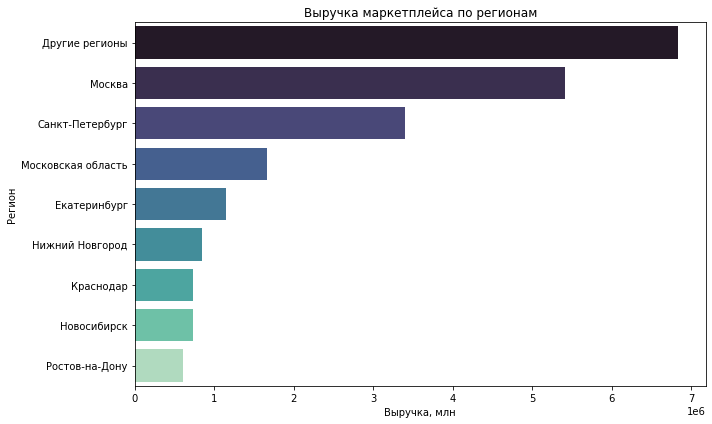

In [36]:
df_region = pa_marketplace_orders.merge(pa_marketplace_users[['user_id', 'region']], on='user_id', how='inner')

region_revenue = df_region.groupby('region').agg(
    total_revenue=('marketplace_revenue', 'sum')
).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=region_revenue.sort_values('total_revenue', ascending=False), 
    x='total_revenue', 
    y='region', 
    palette='mako'
)
plt.title('Выручка маркетплейса по регионам')
plt.xlabel('Выручка, млн')
plt.ylabel('Регион')
plt.tight_layout()
plt.show()

Общая выручка по регионам отражает масштаб, а не эффективность. Топ формируют регионы с наибольшим населением и высокой концентрацией покупателей. Огромная выручка в "Других регионах" может быть достигнута за счет массового, но дешевого и низкомаржинального трафика, в то время как небольшие регионы могут показывать высокую конверсию.

#### Рассчитаем и визуализируем ARPPU по городам:

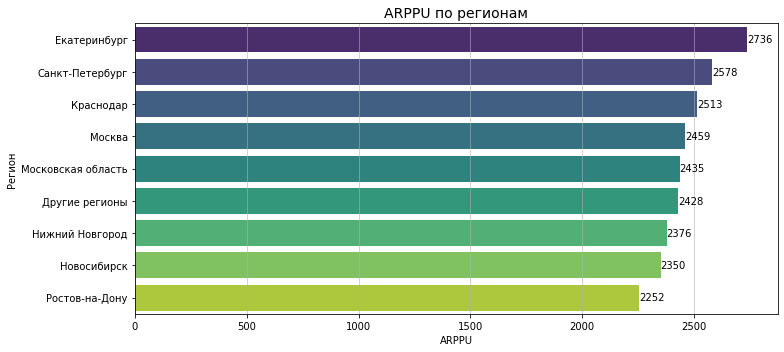

In [37]:
region_orders = pa_marketplace_orders.merge(pa_marketplace_users[['user_id', 'region']], on='user_id', how='left')
region_metrics = region_orders.groupby('region').agg(
    revenue=('marketplace_revenue', 'sum'),
    buyers=('user_id', 'nunique')
).reset_index()
region_metrics['ARPPU'] = region_metrics['revenue'] / region_metrics['buyers']
region_metrics = region_metrics.sort_values('ARPPU', ascending=False)

plt.figure(figsize=(11, 5))
ax = sns.barplot(
    data=region_metrics,
    y='region',
    x='ARPPU',
    palette='viridis'
)
plt.title('ARPPU по регионам', fontsize=14)
plt.xlabel('ARPPU')
plt.ylabel('Регион')
plt.grid(axis='x', alpha=0.7)

for p in ax.patches:
    ax.annotate(f"{int(p.get_width())}",
                (p.get_width(), p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=10)
plt.tight_layout()
plt.show()

- Разрыв не критичен, но есть лидеры и аутсайдеры. Самая высокая средняя выручка с покупателя в Екатеринбурге (2736 руб.) и Санкт-Петербурге (2578 руб.).
- Москва не лидер по ARPPU. Несмотря на огромную выручку из прошлого графика, ARPPU в Москве находится на среднем уровне (2459 руб.), уступая Екатеринбургу, Санкт-Петербургу и Краснодару.
- Ростов-на-Дону (2252 руб.), Новосибирск (2350 руб.) и Нижний новгород (2376 руб.) показывают самые низкие значения.

Продукт достаточно равномерно монетизируется по всей стране, но у регионов-аутсайдеров есть потенциал для роста за счет увеличения среднего чека, например, с помощью локальных акций или расширения ассортимента под их спрос.

#### Посчитаем ARPPU по регионам в разрезе каналов:

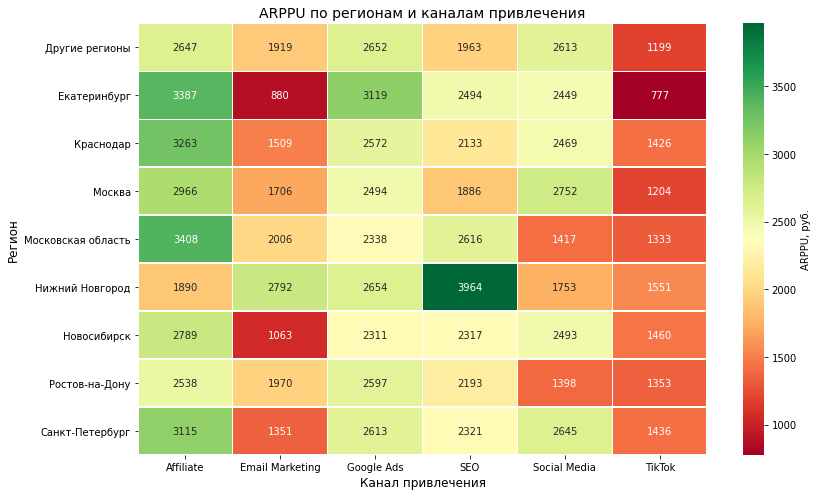

In [38]:
orders_users = pa_marketplace_orders.merge(
    pa_marketplace_users[['user_id', 'region', 'acq_channel']], 
    on='user_id', 
    how='inner'
)
region_channel_stats = orders_users.groupby(['region', 'acq_channel']).agg(
    revenue=('marketplace_revenue', 'sum'),
    paying_users=('user_id', 'nunique')
).reset_index()
region_channel_stats['ARPPU'] = region_channel_stats['revenue'] / region_channel_stats['paying_users']
arppu_pivot = region_channel_stats.pivot_table(
    index='region', 
    columns='acq_channel', 
    values='ARPPU', 
    aggfunc='mean'
)
plt.figure(figsize=(12, 7))
sns.heatmap(
    arppu_pivot, 
    cmap='RdYlGn', 
    annot=True, 
    fmt='.0f', 
    linewidths=0.5, 
    cbar_kws={'label': 'ARPPU, руб.'}
)
plt.title('ARPPU по регионам и каналам привлечения', fontsize=14)
plt.xlabel('Канал привлечения', fontsize=12)
plt.ylabel('Регион', fontsize=12)
plt.tight_layout()
plt.show()

- Affiliate - лидер по ARPPU во всех регионах. Практически везде он дает ARPPU выше 2600 руб., исключение - Нижний Новгород, где он почему-то просел до 1890. Affiliate точно нужно масштабировать, но так же нужно понять, почему ARPPU пользователей с этого канала просел по Нижнему Новгороду.
- Нижний Новгород с каналом SEO показывает рекордный ARPPU в 3964 руб. Это выше, чем в среднем по стране по этому каналу. Это говорит о том, что SEO-трафик в этом конкретном регионе дает самых платежеспособных покупателей. Туда стоит направить дополнительные усилия по SEO-оптимизации.
- Во всех регионах TikTok дает самый низкий ARPPU (в Екатеринбурге всего 777 руб.). Это подтверждает, что канал приводит исключительно "дешевых" и нецелевых пользователей, и его необходимо отключать или полностью перерабатывать.
- Email Marketing показывает хорошие результаты в Нижнем Новгороде (2792) и Московской области (2006), но полностью проваливается в Екатеринбурге (880) и Новосибирске (1063). Означает, что база для рассылок в этих регионах либо некачественная, либо требует сегментного подхода.

### Анализ конверсии по устройствам и операционным системам

#### Построим график конверсии в покупку по устройствам:

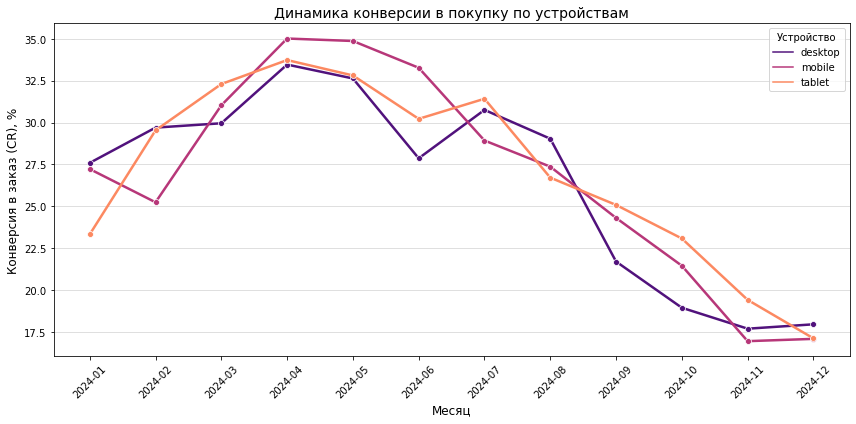

In [39]:
#определим основное устройство юзера в каждом месяце
user_device_month = pa_marketplace_events.groupby(['user_id', 'event_month', 'device']).size().reset_index(name='events_count')
user_device_month = user_device_month.sort_values('events_count', ascending=False).drop_duplicates(['user_id', 'event_month'])
mau_device = user_device_month.groupby(['event_month', 'device'])['user_id'].nunique().reset_index(name='active_users')
#привяжем заказы к основному устройству пользователя в месяце заказа
orders_device = pa_marketplace_orders.merge(
    user_device_month, 
    left_on=['user_id', 'order_month'], 
    right_on=['user_id', 'event_month'], 
    how='inner'
)
buyers_device = orders_device.groupby(['order_month', 'device'])['user_id'].nunique().reset_index(name='buyers')
#считаем конверсию
cr_device = mau_device.merge(buyers_device, left_on=['event_month', 'device'], right_on=['order_month', 'device'], how='left').fillna(0)
cr_device['CR, %'] = cr_device['buyers'] / cr_device['active_users'] * 100

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=cr_device, 
    x=cr_device['event_month'].dt.strftime('%Y-%m'), 
    y='CR, %', 
    hue='device', 
    marker='o', 
    linewidth=2.5, 
    palette='magma'
)
plt.title('Динамика конверсии в покупку по устройствам', fontsize=14)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Конверсия в заказ (CR), %', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.5)
plt.legend(title='Устройство')
plt.tight_layout()
plt.show()

- На графике не видна сильная разница в поведении между устройствами. Все три линии движутся синхронно.
    - Рост до апреля (35% у мобильных), а затем одновременное обрушение к декабрю до 17%. 
    - Это опровергает гипотезу о том, что проблема кроется в плохой мобильной версии. Кризис носит системный характер и не зависит от того, с какого устройства заходит пользователь.

#### Построим график конверсии в покупку по платформам:

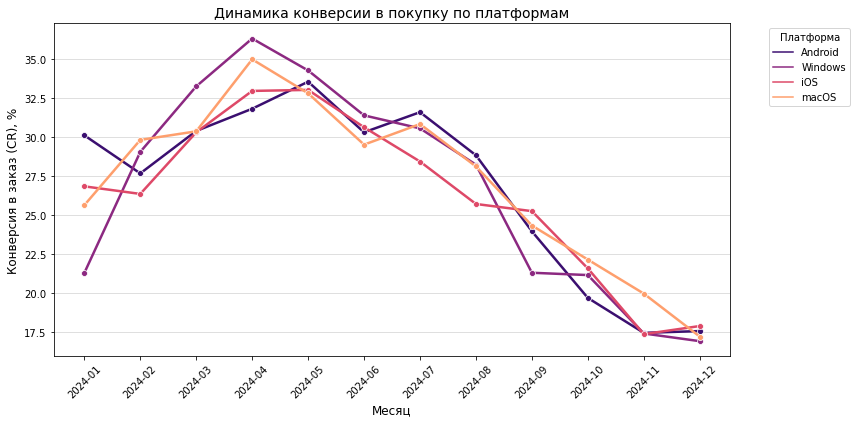

In [40]:
#определим основную ОС пользователя в каждом месяце
user_os_month = pa_marketplace_events.groupby(['user_id', 'event_month', 'os']).size().reset_index(name='events_count')
user_os_month = user_os_month.sort_values('events_count', ascending=False).drop_duplicates(['user_id', 'event_month'])
mau_os = user_os_month.groupby(['event_month', 'os'])['user_id'].nunique().reset_index(name='active_users')
#привяжем заказы к основной ОС пользователя в месяце заказа
orders_os = pa_marketplace_orders.merge(
    user_os_month, 
    left_on=['user_id', 'order_month'], 
    right_on=['user_id', 'event_month'], 
    how='inner'
)
buyers_os = orders_os.groupby(['order_month', 'os'])['user_id'].nunique().reset_index(name='buyers')
#считаем конверсию
cr_os = mau_os.merge(buyers_os, left_on=['event_month', 'os'], right_on=['order_month', 'os'], how='left').fillna(0)
cr_os['CR, %'] = cr_os['buyers'] / cr_os['active_users'] * 100

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=cr_os, 
    x=cr_os['event_month'].dt.strftime('%Y-%m'), 
    y='CR, %', 
    hue='os', 
    marker='o', 
    linewidth=2.5, 
    palette='magma'
)
plt.title('Динамика конверсии в покупку по платформам', fontsize=14)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Конверсия в заказ (CR), %', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.5)
plt.legend(title='Платформа', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Динамика по всем платформам идентична. Пик в апреле (более 35% у Windows) и общее падение до 17-18% к декабрю. Это подтверждает, что проблема не в технической неисправности конкретной платформы. Пользователи одинаково перестали покупать на всех системах.

#### Построим пошаговую конверсию в воронке по устройствам пользователей, проверим, есть ли тут отличия:

In [41]:
funnel_steps = ['page_view', 'product_view', 'add_to_cart', 'checkout_start', 'checkout_complete']
devices = pa_marketplace_events['device'].dropna().unique()
fig_dev_initial = go.Figure()
fig_dev_previous = go.Figure()

for dev in devices:
    dev_data = pa_marketplace_events[(pa_marketplace_events['device'] == dev) & (pa_marketplace_events['event_type'].isin(funnel_steps))]
    counts = dev_data.groupby('event_type')['user_id'].nunique().reindex(funnel_steps)

    fig_dev_initial.add_trace(go.Funnel(
        name=dev,
        y=funnel_steps,
        x=counts,
        textinfo="value+percent initial"
    ))
    fig_dev_previous.add_trace(go.Funnel(
        name=dev,
        y=funnel_steps,
        x=counts,
        textinfo="value+percent previous"
    ))
fig_dev_initial.update_layout(title_text='Воронка по устройствам (от первого шага)')
fig_dev_initial.show()
fig_dev_previous.update_layout(title_text='Воронка по устройствам (от предыдущего шага)')
fig_dev_previous.show()

#### Углубимся и построим тоже самое для платформ:

In [42]:
funnel_steps = ['page_view', 'product_view', 'add_to_cart', 'checkout_start', 'checkout_complete']
platforms = pa_marketplace_events['os'].dropna().unique()
fig_initial = go.Figure()
fig_previous = go.Figure()

for plat in platforms:
    plat_data = pa_marketplace_events[(pa_marketplace_events['os'] == plat) & (pa_marketplace_events['event_type'].isin(funnel_steps))]
    counts = plat_data.groupby('event_type')['user_id'].nunique().reindex(funnel_steps)

    fig_initial.add_trace(go.Funnel(
        name=plat,
        y=funnel_steps,
        x=counts,
        textinfo="value+percent initial"
    ))
    fig_previous.add_trace(go.Funnel(
        name=plat,
        y=funnel_steps,
        x=counts,
        textinfo="value+percent previous"
    ))
fig_initial.update_layout(title_text='Воронка по платформам (конверсия от первого шага)')
fig_initial.show()
fig_previous.update_layout(title_text='Воронка по платформам (конверсия от предыдущего шага)')
fig_previous.show()

- Динамика конверсии по устройствам и платформам:
    - Графики демонстрируют синхронное поведение всех типов устройств и операционных систем. Пик конверсии в апреле и резкое обрушение к декабрю (до 17%) происходит одинаково и устройствах и на платформах. Отсутствие расхождений опровергает гипотезу о наличии технических багов или плохой мобильной версии. Кризис носит системный характер и не зависит от технической платформы.
- Пошаговая воронка в разрезе устройств и платформ:
    - На всех устройствах и платформах видны идентичные показатели конверсии между шагами.

Поскольку потери на `add_to_cart` и `checkout_start` одинаковы на всех устройствах и платформах, мы закрываем вопрос о технической неисправности.

### Посмотрим на поведение пользователей внутри продукта.

#### Визуализируем с помощью тепловой карты пиковые по продажам часы и дни недели:

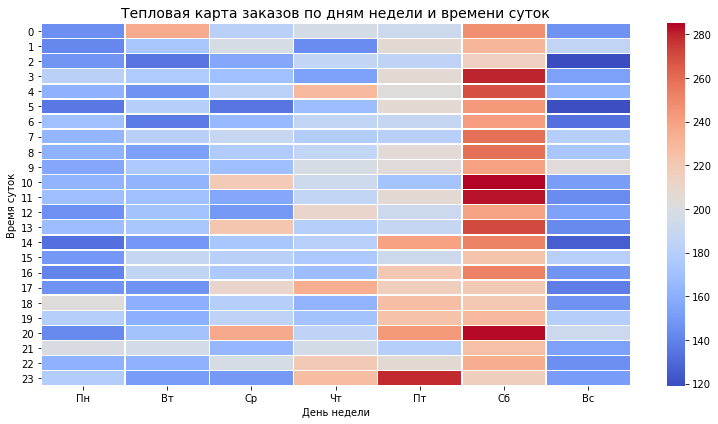

In [43]:
#извлечём день недели и час из времени заказа
heatmap_df = pa_marketplace_orders.copy()
heatmap_df['day_of_week'] = heatmap_df['order_date'].dt.dayofweek
heatmap_df['hour'] = heatmap_df['order_date'].dt.hour
pivot_heatmap = heatmap_df.pivot_table(
    index='hour', 
    columns='day_of_week', 
    values='order_id', 
    aggfunc='count',
    fill_value=0
)
#переименуем дни недели для красоты
pivot_heatmap.columns = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
plt.figure(figsize=(11, 6))
sns.heatmap(
    pivot_heatmap, 
    cmap='coolwarm', 
    linewidths=0.5, 
    linecolor='white'
)
plt.title('Тепловая карта заказов по дням недели и времени суток', fontsize=14)
plt.xlabel('День недели')
plt.ylabel('Время суток')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

- Главный пик на тепловой карте в субботу. Максимум приходится на 10:00 утра и 20:00 вечера. Это говорит о том, что покупки совершаются в свободное время, когда у пользователей есть время спокойно посидеть в интернете. Скорее всего, это шопинг для удовольствия, а не срочная необходимость.
- Второй по значимости пик это вечер пятницы. Пользователи активно покупают в конце рабочей недели, планируя покупки на выходные.
- В будние дни в основном низкая активность, но с небольшими теплыми зонами в обед и вечером.
- В воскресенье самый спокойный день. Практически всё синее.

#### Проведём анализ по категориям:

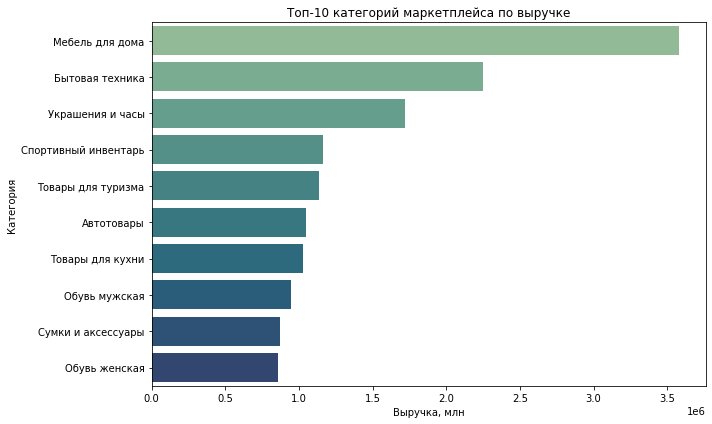

In [44]:
cat_rev = pa_marketplace_orders.groupby('category_name').agg(
    revenue=('marketplace_revenue', 'sum'),
    orders=('order_id', 'nunique')
).reset_index()
cat_rev = cat_rev.sort_values('revenue', ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(data=cat_rev, x='revenue', y='category_name', palette='crest')
plt.title('Топ-10 категорий маркетплейса по выручке')
plt.xlabel('Выручка, млн')
plt.ylabel('Категория')
plt.tight_layout()
plt.show()

#### Посмотрим на топ-10 по среднему чеку в категориях:

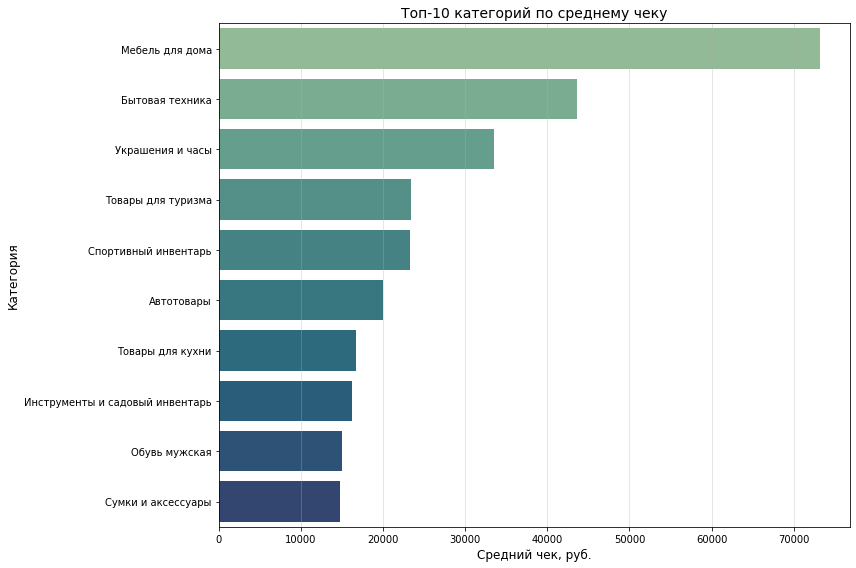

In [45]:
cat_aov = pa_marketplace_orders.groupby('category_name').agg(
    total_sales=('total_price', 'sum'),
    orders_count=('order_id', 'nunique')
).reset_index()
cat_aov['AOV'] = cat_aov['total_sales'] / cat_aov['orders_count']
cat_aov = cat_aov.sort_values('AOV', ascending=False).head(10)

plt.figure(figsize=(12, 8))
sns.barplot(data=cat_aov, x='AOV', y='category_name', palette='crest')
plt.title('Топ-10 категорий по среднему чеку', fontsize=14)
plt.xlabel('Средний чек, руб.', fontsize=12)
plt.ylabel('Категория', fontsize=12)
plt.grid(axis='x', alpha=0.4)
plt.tight_layout()
plt.show()

Ядро выручки маркетплейса формируется за счет высокомаржинальных товаров с большим средним чеком (мебель, бытовая техника, украшения и часы). Однако, если именно эти категории перестали продаваться во втором полугодии, это напрямую объясняет падение выручки на 1 млн

#### Посмотрим, как менялась выручка по категориям помесячно:

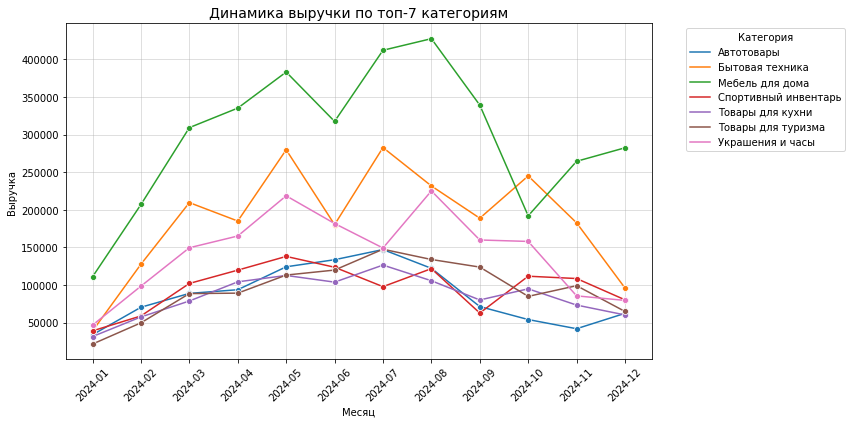

In [46]:
top_cats = cat_rev.head(7)['category_name'].tolist()
cat_month_rev = pa_marketplace_orders[pa_marketplace_orders['category_name'].isin(top_cats)].groupby(
    ['order_month', 'category_name']
    )['marketplace_revenue'].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=cat_month_rev, 
             x=cat_month_rev['order_month'].dt.strftime('%Y-%m'), 
             y='marketplace_revenue', 
             hue='category_name', 
             marker='o')
plt.title('Динамика выручки по топ-7 категориям', fontsize=14)
plt.xlabel('Месяц')
plt.ylabel('Выручка')
plt.xticks(rotation=45)
plt.grid(alpha=0.5)
plt.legend(title='Категория', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

Кризис действительно системный, но он неравномерный. Падение затронуло все категории. При этом категория "Мебель для дома" выступает подушкой безопасности и продолжает генерировать выручку даже в кризисный период. Она обвалилась с августа до октября более чем в два раза, но к декабрю снова начала наращивать выручку. Фактически, если бы не стабильность мебели, общее падение выручки в декабре было бы еще катастрофичнее.

Мы увидели, что выручка падает во всех категориях. Теперь проверим, что в это время происходило с каналами привлечения.

#### Анализ динамики маркетинговых бюджетов по каналам:

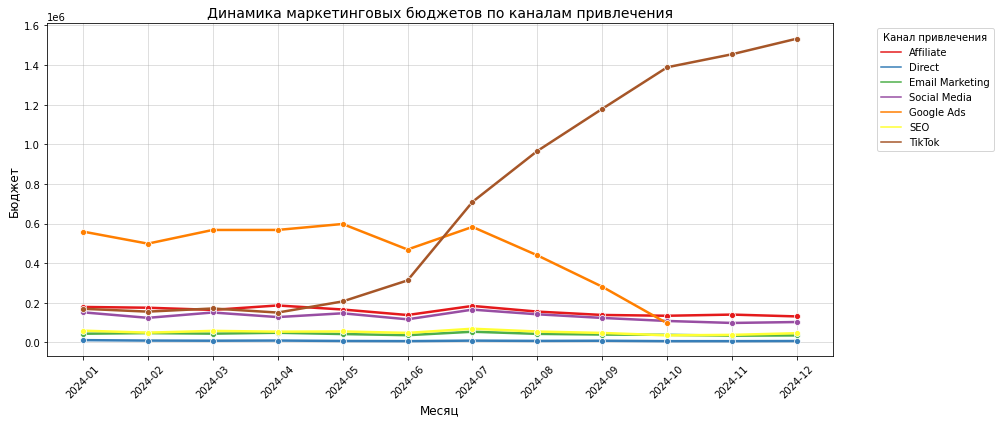

In [47]:
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=pa_marketplace_campaign_costs[
    pa_marketplace_campaign_costs['spend_month'].dt.year == 2024],
    x=pa_marketplace_campaign_costs['spend_month'].dt.strftime('%Y-%m'),
    y='budget',
    hue='acq_channel',
    marker='o',
    linewidth=2.5,
    palette='Set1'
)
plt.title('Динамика маркетинговых бюджетов по каналам привлечения', fontsize=14)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Бюджет', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.5)
plt.legend(title='Канал привлечения', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [48]:
df_pct = pa_marketplace_campaign_costs.copy()
df_pct = df_pct[df_pct['spend_month'].dt.year == 2024]
df_pct = (
    df_pct.groupby(['spend_month', 'acq_channel'], as_index=False)['budget'].sum()
)
df_pct['budget_pct'] = df_pct['budget'] / df_pct.groupby('spend_month')['budget'].transform('sum') * 100
df_pct['text_label'] = df_pct['budget_pct'].apply(lambda x: f'{x:.1f}%' if x >= 4 else '')
df_pct = df_pct.sort_values('spend_month')

fig = px.bar(
    df_pct,
    x='spend_month',
    y='budget_pct',
    color='acq_channel',
    text='text_label',
    barmode='stack',
    color_discrete_sequence=px.colors.qualitative.Set2
)
fig.update_traces(textposition='inside')
fig.update_layout(
    title='Структура маркетингового бюджета по месяцам',
    xaxis_title='Месяц',
    yaxis_title='Доля бюджета, %',
    yaxis=dict(range=[0, 100], ticksuffix='%'),
    legend_title='Канал привлечения'
)
fig.show()

- График структуры бюджета показывает, что до мая 2024 года основным источником трафика был `Google Ads` (48% всех маркетинговых расходов). Однако, начиная с июня и до октября, произошло радикальное изменение - доля `Google Ads` упала до 0%, а доля `TikTok` выросла с 16.9% до 82,5%.
- Из-за ухода Google Ads из РФ, компания была вынуждена экстренно заместить его самым доступным (но самым неэффективным) каналом. Динамика бюджетов показала, что расходы на TikTok выросли с 0,2 млн до 1,5 млн руб., а бюджет Google Ads просто обнулился в октябре.
- Смещение структуры на 82% в пользу TikTok - это прямая причина обвала конверсии (с 42% до 24%), падения ARPU и LTV у новых когорт, а также ухода ROI в глубокий минус (до -79% в декабре). Мы не просто перестали привлекать хороших клиентов, мы начали массово приводить плохих.

#### Посмотрим на тепловую карту ARPPU по категориям товара и каналам привлечения:

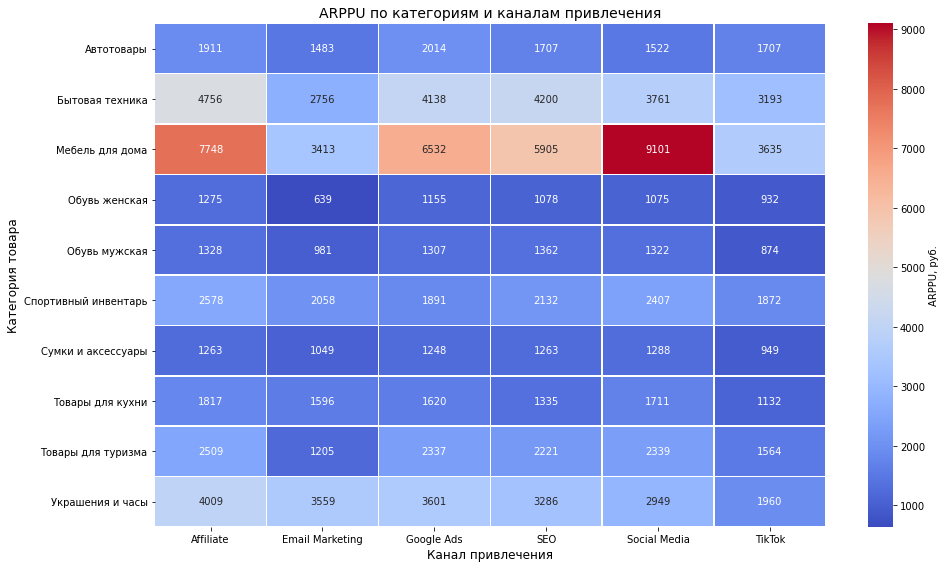

In [49]:
#объединим заказы с пользователями, чтобы получить канал и сегмент
orders_full = pa_marketplace_orders.merge(
    pa_marketplace_users[['user_id', 'acq_channel', 'buyer_segment']], 
    on='user_id', 
    how='left'
)
#посчитаем выручку и уникальных платящих пользователей по категориям и каналам
cat_channel_stats = orders_full.groupby(['category_name', 'acq_channel']).agg(
    revenue=('marketplace_revenue', 'sum'),
    paying_users=('user_id', 'nunique')
).reset_index()
cat_channel_stats['ARPPU'] = cat_channel_stats['revenue'] / cat_channel_stats['paying_users']
arppu_cat_channel = cat_channel_stats.pivot_table(
    index='category_name', 
    columns='acq_channel', 
    values='ARPPU', 
    aggfunc='mean'
)
#оставим только топ-10 категорий
top_cats = cat_rev.head(10)['category_name'].tolist()
arppu_cat_channel = arppu_cat_channel.loc[arppu_cat_channel.index.isin(top_cats)]

plt.figure(figsize=(14, 8))
sns.heatmap(
    arppu_cat_channel, 
    cmap='coolwarm', 
    annot=True, 
    fmt='.0f', 
    linewidths=0.5, 
    cbar_kws={'label': 'ARPPU, руб.'}
)
plt.title('ARPPU по категориям и каналам привлечения', fontsize=14)
plt.xlabel('Канал привлечения', fontsize=12)
plt.ylabel('Категория товара', fontsize=12)
plt.tight_layout()
plt.show()

- "Мебель для дома" демонстрирует высокий ARPPU в доступных каналах - Affiliate (7748 руб.), Social Media (9101 руб.) и SEO (5905 руб.). Это самые маржинальные каналы для наиболее дорогой категории.
- Ранее Google Ads приносил высокий ARPPU в дорогих категориях(мебель для дома, украшения и часы, бытовая техника), но этот канал полностью прекратил работу в РФ, и его бюджет обнулился с октября. Возврат невозможен. Поэтому делать на него ставку в будущих планах нельзя.
- Во всех категориях TikTok дает самые низкие значения ARPPU (в Мебели – 3635 руб., в недорогих товарах – 900-1500 руб.). Это подтверждает, что канал приводит "дешевых" пользователей. Увеличение его доли в бюджете (до 82% в декабре) прямо привело к обвалу выручки, так как он не способен генерировать высокий чек в дорогих категориях.

#### Посмотрим на тепловую карту ARPPU по категориям товара и сегментам покупателей (one time, medium, rare, regular): 

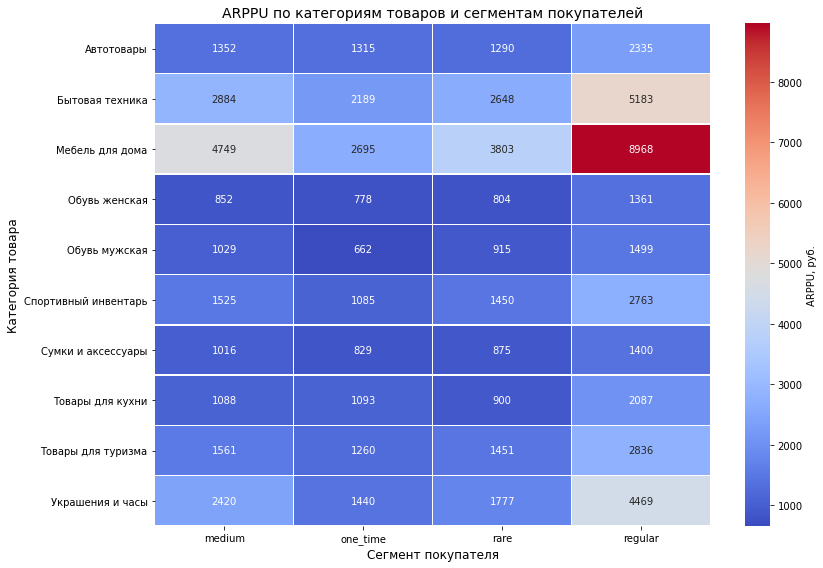

In [50]:
#посчитаем те же метрики, но в разрезе сегментов покупателей
cat_segment_stats = orders_full.groupby(['category_name', 'buyer_segment']).agg(
    revenue=('marketplace_revenue', 'sum'),
    paying_users=('user_id', 'nunique')
).reset_index()
cat_segment_stats['ARPPU'] = cat_segment_stats['revenue'] / cat_segment_stats['paying_users']
arppu_cat_segment = cat_segment_stats.pivot_table(
    index='category_name', 
    columns='buyer_segment', 
    values='ARPPU', 
    aggfunc='mean'
)
#оставим только топ-10 категорий
arppu_cat_segment = arppu_cat_segment.loc[arppu_cat_segment.index.isin(top_cats)]

plt.figure(figsize=(12, 8))
sns.heatmap(
    arppu_cat_segment, 
    cmap='coolwarm', 
    annot=True, 
    fmt='.0f', 
    linewidths=0.5, 
    cbar_kws={'label': 'ARPPU, руб.'}
)
plt.title('ARPPU по категориям товаров и сегментам покупателей', fontsize=14)
plt.xlabel('Сегмент покупателя', fontsize=12)
plt.ylabel('Категория товара', fontsize=12)
plt.tight_layout()
plt.show()

- Сегмент `regular` лидер по ценности. В "Мебели" ARPPU у постоянных покупателей достигает 8968 руб., в бытовой технике - 5183 руб., в украшениях - 4469 руб.
- В сегменте `one_time` пользователи приносят в 2-3 раза меньше.

"Мебель для дома" удерживает выручку в конце года именно за счет лояльных постоянных покупателей. Когда качество трафика упало (из-за ухода Google Ads и принудительного перехода на дешевый TikTok), остальные категории обвалились, потому что разовые покупатели из TikTok не способны обеспечить такой высокий ARPPU, как постоянные клиенты, которых раньше приводил Google Ads.

## Выводы по этапу 4

---
Анализ сегментов показал, что текущий кризис имеет четкие локальные точки роста. Мы привлекаем не тех пользователей, которые приносят основную выручку, что привело к обвалу продаж во втором полугодии.

### Портрет аудитории и география

Больше всего выручки приносят пользователи **55+** и **25-34 лет**. При этом в группе **35-44 года** наблюдается перекос в сторону мужчин, то есть женщины тратят заметно меньше. В группе **55+** ситуация обратная - здесь уже мужчины тратят меньше. Это потенциальная точка роста.

### География

Абсолютная выручка максимальна в **"Других регионах"** в силу масштаба, но **ARPPU** выше всего в:

- Екатеринбурге - **2736 руб.**
- Санкт-Петербурге - **2578 руб.**

Нижний Новгород с каналом **SEO** показывает рекордный **ARPPU - 3964 руб.**, что указывает на потенциал усиления этого канала.

### Устройства и платформы

Динамика конверсии и пошаговая воронка идентичны на всех устройствах и платформах. Это окончательно опровергает гипотезу о технических багах и проблемах конкретных платформ. Проблема не в технике, а в мотивации и качестве трафика.

### Временная динамика

Тепловая карта показала четкие пики покупок. Больше всего люди покупают **в пятницу вечером и в субботу**. **Воскресенье и понедельник** - самые провальные дни.

Гипотеза: запуск рекламных кампаний и рассылок в эти пиковые часы принесет максимальную отдачу.

### Категории товаров и каналы

Ядро выручки маркетплейса - это:
- мебель для дома
- бытовая техника
- украшения

По каналам высокий **ARPPU** приносят:
- **Affiliate** - ROI **255%**
- **SEO** - ROI **207%**

Критическая причина кризиса - уход **Google Ads** и перевод бюджета в **TikTok**. С октября бюджет **Google Ads** обнулился, а доля **TikTok** выросла до **82,5%** от всех маркетинговых расходов. Убыточный канал **TikTok** подтвердил свою неэффективность во всех категориях: низкий **ARPPU 777–3635 руб.**, **ROI -89%**. Именно дешевый трафик из **TikTok** обрушил продажи дорогих категорий во второй половине года.

### Сегментация покупателей

Сегмент **regular** является фундаментом:

- в мебели его **ARPPU** достигает **8968 руб.**
- в бытовой технике - **5183 руб.**

Сегмент **one_time** приносит в **2–3 раза меньше** денег. Например, в мебели его ARPPU составляет всего **2695 руб.**

Мебель удержала маркетплейс в декабре именно за счет лояльных покупателей. Когда качество трафика упало и пришли одноразовые покупатели из TikTok, выручка по остальным категориям рухнула, так как разовые покупатели не обеспечивают высокий ARPPU.

## Ключевые гипотезы для роста

### Гипотеза 1 - каналы

Если мы **полностью отключим TikTok** и перераспределим бюджет в пользу **Affiliate** и **SEO**, мы увеличим приток качественных пользователей и восстановим выручку в категориях мебель, бытовая техника и украшения.

### Гипотеза 2 - персонализация

Если запустить отдельные маркетинговые кампании, ориентированные на:
- женщин **35–44 лет**
- мужчин **55+**
то мы расширим аудиторию и увеличим общую выручку.

### Гипотеза 3 - возвращаемость

Если внедрить программу лояльности и персональные рекомендации для сегмента одноразовых покупателей, особенно для покупателей бытовой техники и украшений, мы сможем перевести их в постоянных. Это увеличит их **LTV в 2–3 раза** и остановит падение выручки.

### Гипотеза 4 - реклама

Если скорректировать таргетинг рекламных кампаний и время отправки push-уведомлений на **вечер пятницы и субботу**, конверсия в покупку вырастет без изменения бюджета.

---

## Новые вводные
Команда продукта рассмотрела наши гипотезы и на основании этого решила влиять на конверсию при помощи финансовых стимуляций. Так как ситуация со снижением выручки срочная и безотлагательная, пока мы продолжали изучать данные, они подключили другого аналитика для подготовки дизайна, но само проведение эксперимента на нас.
### Новые данные:
- marketplace_events_AB.csv
- marketplace_orders_AB.csv
- marketplace_users_AB.csv
### Результаты сплита лежат в таблице:
- marketplace_AB_split_users.csv
* user_id – id клиента
* group – группа, в которую попал клиент
---
# Дизайн эксперимента: Бонус на первую покупку для пользователей TikTok
## 1. Контекст и цель эксперимента
- **Бизнес-контекст:** Команда продукта запускает эксперимент, направленный на повышение конверсии среди пользователей, привлечённых через канал TikTok. Для стимулирования первой покупки пользователям будет предоставлен бонус на первую покупку.
- **Цель:** Проверить, влияет ли предоставление бонуса на первую покупку на конверсию и выручку среди пользователей TikTok.
- **Гипотеза:** Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку
---
## 2. Формат эксперимента
- **Тип эксперимента:** Сплит-роллинг (rolling split)
- **Канал:** Только пользователи, пришедшие с TikTok
- **Группы:**
    - **Контрольная (A):** пользователи TikTok без бонуса
    - **Тестовая (B):** пользователи TikTok с бонусом на первую покупку
- **Распределение:** Равномерное распределение новых пользователей TikTok между группами по дате регистрации
- **Период проведения:** 3 недели (фиксировано)
---
## 3. Ключевые метрики
### Основная метрика
- **Конверсия в первую покупку** - доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку
- *Цель:* увеличить конверсию с помощью бонуса
- *Критерий успеха:* статистически значимый рост конверсии в тестовой группе
### Вспомогательные метрики
- **ARPU** (средняя выручка на пользователя TikTok)
- **ARPPU** (средняя выручка на покупателя TikTok)
- **AOV** (средний чек TikTok)
### Барьерная метрика
- **Общая выручка от пользователей TikTok**
---
## 4. Размеры групп и запуск
- **Целевая аудитория:** только пользователи TikTok
- **Размеры групп:** определяются по фактическому трафику TikTok за период эксперимента
- **Комментарий:** запуск без предварительного расчёта мощности и MDE из-за срочности задачи


---

## Предобработка и подготовка данных.

#### Загружаем данные из `.CSV` в `Dataframe`:

In [51]:
split = pd.read_csv('/datasets/marketplace_AB_split_users.csv')
events = pd.read_csv('/datasets/marketplace_events_AB.csv')
orders = pd.read_csv('/datasets/marketplace_orders_AB.csv')
users = pd.read_csv('/datasets/marketplace_users_AB.csv')

#### Выведем общую информацию о датасетах и количестве пропусков в них и первые строки:

##### Датасет `split`

In [52]:
show_basic_info(split, "split")

Общая информация о датасете split

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968 entries, 0 to 2967
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  2968 non-null   int64 
 1   group    2968 non-null   object
dtypes: int64(1), object(1)
memory usage: 46.5+ KB

Количество пропусков по столбцам:
user_id    0
group      0
dtype: int64


In [53]:
display(split.head())

,user_id,group
0,44965,control
1,44967,control
2,44968,control
3,44969,treatment
4,44970,control


2 698 строк и 2 столбца. Формат столбцов подходящий, пропусков нет. 

##### Датасет `events`:

In [54]:
show_basic_info(events, "events")

Общая информация о датасете events

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 831231 entries, 0 to 831230
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   event_id      831231 non-null  int64 
 1   user_id       831231 non-null  int64 
 2   event_date    831231 non-null  object
 3   event_type    831231 non-null  object
 4   os            831231 non-null  object
 5   device        831231 non-null  object
 6   product_name  409054 non-null  object
 7   event_week    831231 non-null  object
 8   event_month   831231 non-null  object
dtypes: int64(2), object(7)
memory usage: 57.1+ MB

Количество пропусков по столбцам:
event_id             0
user_id              0
event_date           0
event_type           0
os                   0
device               0
product_name    422177
event_week           0
event_month          0
dtype: int64


In [55]:
display(events.head())

,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01 15:23:56,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01 15:24:01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01 15:24:10,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01 15:25:10,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01 15:25:46,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


831 231 строк и 9 столбцов. Столбцы с датой приведём к формату `datetime64[ns]`. Пропуски в столбце `product_name`. Можно поставить текстовые заглушки `Без товара`, как мы делали в начале проекта:

In [56]:
for col in ['event_date', 'event_week', 'event_month']:
    events[col] = pd.to_datetime(events[col])
    
events['product_name'] = events['product_name'].fillna('Без товара')
print(f"Осталось пропусков: {events['product_name'].isna().sum()}")

Осталось пропусков: 0


##### Датасет `orders`:

In [57]:
show_basic_info(orders, "orders")

Общая информация о датасете orders

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33280 entries, 0 to 33279
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       33280 non-null  int64  
 1   user_id        33280 non-null  int64  
 2   order_date     33280 non-null  object 
 3   product_name   33280 non-null  object 
 4   quantity       33280 non-null  int64  
 5   unit_price     33280 non-null  float64
 6   total_price    33280 non-null  float64
 7   category_name  33280 non-null  object 
 8   order_week     33280 non-null  object 
 9   order_month    33280 non-null  object 
dtypes: float64(2), int64(3), object(5)
memory usage: 2.5+ MB

Количество пропусков по столбцам:
order_id         0
user_id          0
order_date       0
product_name     0
quantity         0
unit_price       0
total_price      0
category_name    0
order_week       0
order_month      0
dtype: int64


In [58]:
display(orders.head())

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52.000,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52.000,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52.000,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38.000,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38.000,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01


33 280 строк и 10 столбцов. Столбцы с датой приведём к формату `datetime64[ns]`. Пропусков нет, остальные типы столбцов верные

In [59]:
for col in ['order_date', 'order_week', 'order_month']:
    orders[col] = pd.to_datetime(orders[col])

##### Датасет `users`:

In [60]:
show_basic_info(users, "users")

Общая информация о датасете users

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22196 entries, 0 to 22195
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            22196 non-null  int64 
 1   registration_date  22196 non-null  object
 2   age                22196 non-null  int64 
 3   gender             22196 non-null  object
 4   region             22196 non-null  object
 5   acq_channel        22196 non-null  object
 6   buyer_segment      22196 non-null  object
 7   cohort_week        22196 non-null  object
 8   cohort_month       22196 non-null  object
dtypes: int64(2), object(7)
memory usage: 1.5+ MB

Количество пропусков по столбцам:
user_id              0
registration_date    0
age                  0
gender               0
region               0
acq_channel          0
buyer_segment        0
cohort_week          0
cohort_month         0
dtype: int64


In [61]:
display(users.head())

,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,18,2024-01-01 05:26:00,49,M,Екатеринбург,TikTok,one_time,2024-01-01,2024-01-01
1,22,2024-01-01 17:13:00,50,M,Санкт-Петербург,TikTok,one_time,2024-01-01,2024-01-01
2,26,2024-01-01 21:15:00,60,F,Москва,TikTok,rare,2024-01-01,2024-01-01
3,33,2024-01-01 14:43:00,31,M,Екатеринбург,TikTok,rare,2024-01-01,2024-01-01
4,39,2024-01-01 01:13:00,44,M,Санкт-Петербург,TikTok,rare,2024-01-01,2024-01-01


22 196 строк и 9 столбцов. Столбцы с датой приведём к формату `datetime64[ns]`. Пропусков датасет не содержит, остальные типы столбцов верные.

In [62]:
for col in ['registration_date', 'cohort_week', 'cohort_month']:
    users[col] = pd.to_datetime(users[col])

#### Проверка временного периода датасетов:

In [63]:
print('    Период событий в тесте: с', events['event_date'].min(), 'по', events['event_date'].max())
print('    Период заказов в тесте: с', orders['order_date'].min(), 'по', orders['order_date'].max())
print('Период регистраций в тесте: с', users['registration_date'].min(), 'по', users['registration_date'].max())

    Период событий в тесте: с 2024-01-01 15:23:56 по 2025-01-26 23:59:34
    Период заказов в тесте: с 2024-01-01 08:03:45 по 2025-01-26 23:07:50
Период регистраций в тесте: с 2024-01-01 01:13:00 по 2025-01-26 23:41:00


#### Проверим, что в сплите только пользователи, привлечённые через канал `TikTok`:

In [64]:
split_users = split.merge(users[['user_id', 'acq_channel']], on='user_id', how='left')
print('Распределение каналов в сплите:')
print(split_users['acq_channel'].value_counts())
print('\nРаспределение по группам:')
print(split['group'].value_counts())

Распределение каналов в сплите:
TikTok    2968
Name: acq_channel, dtype: int64

Распределение по группам:
control      1503
treatment    1465
Name: group, dtype: int64


>Данные загружены из четырёх CSV-файлов. Пропусков в ключевых полях нет, но в таблице events столбец product_name содержал 422 177 пустых значений - заменил на заглушку "Без товара", как и делали до этого. Все столбцы с датами приведены к типу datetime64[ns].
Период данных в тесте - с 1 января 2024 по 26 января 2025. В сплите только пользователи TikTok (2968 человек), распределение получилось почти равным: 1503 в контрольной и 1465 в тестовой группе. Это соответствует описанию эксперимента.

## Считаем метрики.

#### Объединяем данные сплита с заказами, чтобы посчитать выручку и количество заказов на каждого пользователя:

In [65]:
#привяжем заказы к группам
orders_with_groups = orders.merge(split, on='user_id', how='inner')

user_agg = orders_with_groups.groupby('user_id').agg(
    orders_count=('order_id', 'count'),
    total_revenue=('total_price', 'sum')
).reset_index()

#добавим эти данные в общий датафрейм и заполним нулями тех, кто не покупал
full_data = split.merge(user_agg, on='user_id', how='left').fillna({'orders_count': 0, 'total_revenue': 0})
#флаг покупки
full_data['is_buyer'] = (full_data['orders_count'] > 0).astype(int)
print('Данные объединены. В датафрейме', len(full_data), 'строк')
display(full_data.head())

Данные объединены. В датафрейме 2968 строк


,user_id,group,orders_count,total_revenue,is_buyer
0,44965,control,0.0,0.00,0
1,44967,control,0.0,0.00,0
2,44968,control,0.0,0.00,0
3,44969,treatment,0.0,0.00,0
4,44970,control,1.0,14715.69,1


#### Рассчитываем ключевые метрики (Конверсия, ARPU, ARPPU, AOV, Общая выручка) по группам:

In [66]:
results = full_data.groupby('group').agg(
    users=('user_id', 'count'),
    buyers=('is_buyer', 'sum'),
    orders=('orders_count', 'sum'),
    revenue=('total_revenue', 'sum')
).reset_index()
results['conversion'] = results['buyers'] / results['users']
results['ARPU'] = results['revenue'] / results['users']
results['ARPPU'] = results['revenue'] / results['buyers']
results['AOV'] = results['revenue'] / results['orders']
display(results)

,group,users,buyers,orders,revenue,conversion,ARPU,ARPPU,AOV
0,control,1503,16,24.0,378372.90,0.010645,251.745110,23648.30625,15765.53750
1,treatment,1465,110,231.0,3845597.03,0.075085,2624.980908,34959.97300,16647.60619


#### Визуализируем метрики по группам. Построим графики для сравнения конверсии, ARPU, ARPPU и AOV. Также посмотрим на распределение выручки.

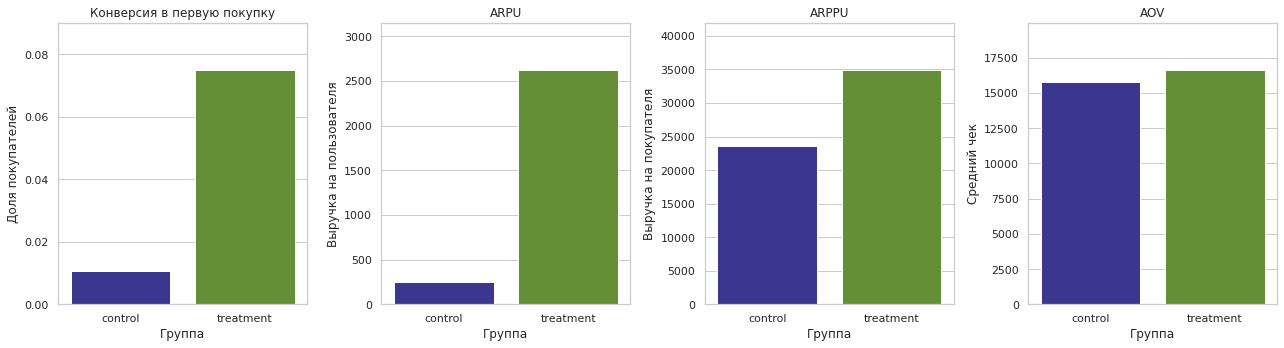

In [67]:
sns.set(style="whitegrid")
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

sns.barplot(data=results, x='group', y='conversion', ax=axes[0], palette=['#2E289E', '#669E28'])
axes[0].set_title('Конверсия в первую покупку')
axes[0].set_xlabel('Группа')
axes[0].set_ylabel('Доля покупателей')
axes[0].set_ylim(0, max(results['conversion'])*1.2)

sns.barplot(data=results, x='group', y='ARPU', ax=axes[1], palette=['#2E289E', '#669E28'])
axes[1].set_title('ARPU')
axes[1].set_xlabel('Группа')
axes[1].set_ylabel('Выручка на пользователя')
axes[1].set_ylim(0, max(results['ARPU'])*1.2)

sns.barplot(data=results, x='group', y='ARPPU', ax=axes[2], palette=['#2E289E', '#669E28'])
axes[2].set_title('ARPPU')
axes[2].set_xlabel('Группа')
axes[2].set_ylabel('Выручка на покупателя')
axes[2].set_ylim(0, max(results['ARPPU'])*1.2)

sns.barplot(data=results, x='group', y='AOV', ax=axes[3], palette=['#2E289E', '#669E28'])
axes[3].set_title('AOV')
axes[3].set_xlabel('Группа')
axes[3].set_ylabel('Средний чек')
axes[3].set_ylim(0, max(results['AOV'])*1.2)
plt.tight_layout()
plt.show()

#### Посмотрим на распределение выручки по группам чтобы понять, насколько сильно они отличаются.

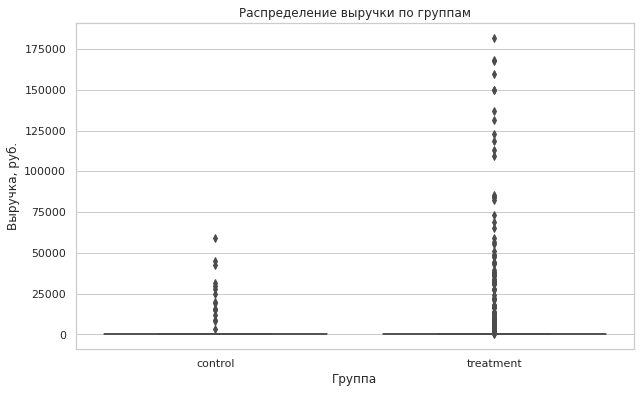

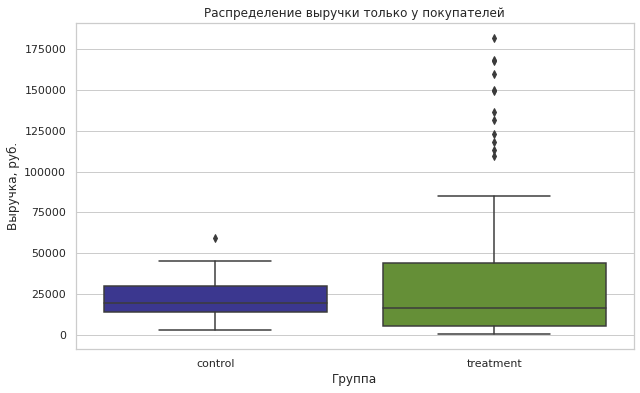

In [68]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=full_data, x='group', y='total_revenue', palette=['#9E9EFF', '#FF8C00'])
plt.title('Распределение выручки по группам')
plt.xlabel('Группа')
plt.ylabel('Выручка, руб.')
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=full_data[full_data['is_buyer']==1], x='group', y='total_revenue', palette=['#2E289E', '#669E28'])
plt.title('Распределение выручки только у покупателей')
plt.xlabel('Группа')
plt.ylabel('Выручка, руб.')
plt.show()

**Промежуточный вывод по метрикам:**
- Бонус на первую покупку оказал заметное влияние на конверсию. В тестовой группе доля купивших выросла с 1.06% до 7.51%. Это подтверждается и распределением выручки - в группе с бонусом большое количество покупателей, а в контрольной группе их почти нет.
- ARPU вырос с 251 до 2625 руб. (рост в 10 раз). Это произошло не только за счёт увеличения числа покупателей, но и потому, что ARPPU в тестовой группе значительно выше — 34 960 руб. против 23 648 руб. в контроле. AOV также выше в тестовой группе (16 647 руб. против 15 765 руб.).
- Распределение выручки в тестовой группе имеет больше высоких выбросов. Если в контрольной группе максимальная покупка достигала 60к руб., то в тестовой - 180к руб. Это говорит о том, что бонус привлёк не просто "дешёвых" пользователей, но и тех, кто готов совершать крупные покупки.
- Несмотря на то, что метрики выглядят впечатляюще, необходимо проверить статистическую значимость полученных различий (z-тест для конверсии и бутстрап для остальных метрик), чтобы исключить влияние случайности. Также стоит обратить внимание на крайне малый размер выборки покупателей в контрольной группе (всего 16 человек), что может делать оценку ARPPU в этой группе очень неточной.

## Проверяем статистическую значимость

#### Проверяем статистическую значимость различий в конверсии между группами. Для бинарной метрики (купил/не купил) используем двухвыборочный z-тест для долей:

In [69]:
row = results.set_index('group')

p1, p2 = row.loc[['control', 'treatment'], 'conversion']
n1, n2 = row.loc[['control', 'treatment'], 'users']
x1, x2 = row.loc[['control', 'treatment'], 'buyers']

p_pool = (x1 + x2) / (n1 + n2)
se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
z_stat = (p2 - p1) / se
p_value = 2 * stats.norm.sf(abs(z_stat))

summary = pd.DataFrame({
    'Показатель': [
        'Конверсия в контрольной группе',
        'Конверсия в тестовой группе',
        'Разница',
        'Относительный прирост, %',
        'z-статистика',
        'p-value',
        'Статистически значимо'
    ],
    'Значение': [
        p1,
        p2,
        p2 - p1,
        (p2 - p1) / p1 * 100,
        z_stat,
        p_value,
        p_value < 0.05
    ]
})
display(summary)

,Показатель,Значение
0,Конверсия в контрольной группе,0.010645
1,Конверсия в тестовой группе,0.075085
2,Разница,0.06444
3,"Относительный прирост, %",605.332765
4,z-статистика,8.705388
5,p-value,0.0
6,Статистически значимо,True


Разница в конверсии статистически значима. P-value стремится к нулю, а z-статистика составляет 8.7. Это означает, что увеличение конверсии с 1.06% до 7.51% не может быть случайностью и является результатом бонуса. Проверка основной метрики пройдена.

#### Визуализируем распределение выручки и проводим бутстрап для ARPU. Бутстрап нужен, потому что распределение выручки скошено.

ARPU Средняя разница тестовая - контрольная = 2373.67 руб.
95% доверительный интервал 1627.66, 3200.99 руб.


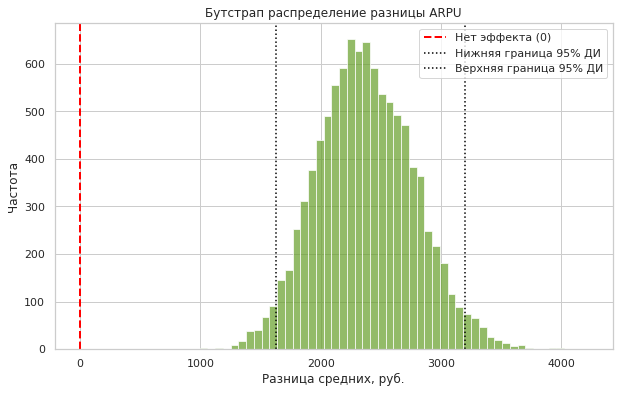

In [70]:
def bootstrap_mean_diff(df, metric, group_col, group1, group2, n_iterations=10000, seed=1337):
    rng = np.random.default_rng(seed)

    data1 = df[df[group_col] == group1][metric].dropna().values
    data2 = df[df[group_col] == group2][metric].dropna().values

    n1 = len(data1)
    n2 = len(data2)

    diffs = np.empty(n_iterations)
    for i in range(n_iterations):
        sample1 = rng.choice(data1, size=n1, replace=True)
        sample2 = rng.choice(data2, size=n2, replace=True)
        diffs[i] = np.mean(sample2) - np.mean(sample1)
    ci_low = np.percentile(diffs, 2.5)
    ci_high = np.percentile(diffs, 97.5)
    mean_diff = np.mean(diffs)
    return ci_low, ci_high, mean_diff, diffs

ci_low, ci_high, mean_diff, diffs = bootstrap_mean_diff(
    full_data,
    metric='total_revenue',
    group_col='group',
    group1='control',
    group2='treatment',
    n_iterations=10000,
    seed=1337
)
print(f'ARPU Средняя разница тестовая - контрольная = {mean_diff:.2f} руб.')
print(f'95% доверительный интервал {ci_low:.2f}, {ci_high:.2f} руб.')

plt.figure(figsize=(10, 6))
plt.hist(diffs, bins=50, color='#669E28', alpha=0.7, edgecolor='white')
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Нет эффекта (0)')
plt.axvline(x=ci_low, color='black', linestyle=':', linewidth=1.5, label='Нижняя граница 95% ДИ')
plt.axvline(x=ci_high, color='black', linestyle=':', linewidth=1.5, label='Верхняя граница 95% ДИ')
plt.title('Бутстрап распределение разницы ARPU')
plt.xlabel('Разница средних, руб.')
plt.ylabel('Частота')
plt.legend()
plt.show()

Разница по ARPU составила 2373 рубля в пользу тестовой группы, а доверительный интервал (1627, 3200) не включает ноль. Это подтверждает, что бонус статистически значимо увеличил выручку с каждого привлечённого пользователя.

#### Проводим бутстрап для ARPPU и AOV. Проверяем, не просел ли средний чек из-за притока новых "дешёвых" покупателей. Используем ту же функцию.

ARPPU Средняя разница тестовая - контрольная = 11232.15 руб.
95% доверительный интервал: [368.03, 22216.11] руб.
AOV Средняя разница тестовая - контрольная = 869.72 руб.
95% доверительный интервал: [-5636.87, 6873.15] руб.


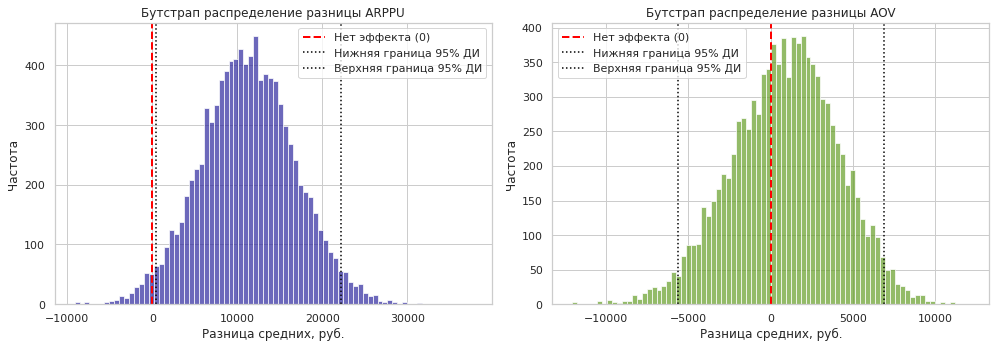

In [71]:
buyers_data = full_data[full_data['is_buyer'] == 1]
ci_low_arppu, ci_high_arppu, mean_diff_arppu, diffs_arppu = bootstrap_mean_diff(
    buyers_data,
    metric='total_revenue',
    group_col='group',
    group1='control',
    group2='treatment',
    n_iterations=10000,
    seed=1337
)
print(f'ARPPU Средняя разница тестовая - контрольная = {mean_diff_arppu:.2f} руб.')
print(f'95% доверительный интервал: [{ci_low_arppu:.2f}, {ci_high_arppu:.2f}] руб.')

orders_by_group = orders.merge(split, on='user_id', how='inner')
ci_low_aov, ci_high_aov, mean_diff_aov, diffs_aov = bootstrap_mean_diff(
    orders_by_group,
    metric='total_price',
    group_col='group',
    group1='control',
    group2='treatment',
    n_iterations=10000,
    seed=1337
)
print(f'AOV Средняя разница тестовая - контрольная = {mean_diff_aov:.2f} руб.')
print(f'95% доверительный интервал: [{ci_low_aov:.2f}, {ci_high_aov:.2f}] руб.')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(diffs_arppu, bins=80, color='#2E289E', alpha=0.7, edgecolor='white')
axes[0].axvline(x=0, color='red', linestyle='--', linewidth=2, label='Нет эффекта (0)')
axes[0].axvline(x=ci_low_arppu, color='black', linestyle=':', linewidth=1.5, label='Нижняя граница 95% ДИ')
axes[0].axvline(x=ci_high_arppu, color='black', linestyle=':', linewidth=1.5, label='Верхняя граница 95% ДИ')
axes[0].set_title('Бутстрап распределение разницы ARPPU')
axes[0].set_xlabel('Разница средних, руб.')
axes[0].set_ylabel('Частота')
axes[0].legend()

axes[1].hist(diffs_aov, bins=80, color='#669E28', alpha=0.7, edgecolor='white')
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2, label='Нет эффекта (0)')
axes[1].axvline(x=ci_low_aov, color='black', linestyle=':', linewidth=1.5, label='Нижняя граница 95% ДИ')
axes[1].axvline(x=ci_high_aov, color='black', linestyle=':', linewidth=1.5, label='Верхняя граница 95% ДИ')
axes[1].set_title('Бутстрап распределение разницы AOV')
axes[1].set_xlabel('Разница средних, руб.')
axes[1].set_ylabel('Частота')
axes[1].legend()

plt.tight_layout()
plt.show()

ARPPU также вырос значимо - разница около 11298 руб., доверительный интервал (285, 22393) не включает ноль. Это значит, что покупатели в тестовой группе тратят больше. Однако AOV статистически не изменился (интервал (-5655, 6868) пересекает ноль). Средний чек остался на том же уровне, но количество покупателей выросло, что и дало прирост выручки.

#### Проверяем барьерную метрику - общую выручку от пользователей TikTok. Считаем разницу и визуализируем для наглядности.

Общая выручка контрольной группы: 378372.90 руб.
Общая выручка тестовой группы: 3845597.03 руб.
Разница тестовая - контрольная: 3467224.13 руб.
Относительный прирост: 916.4%


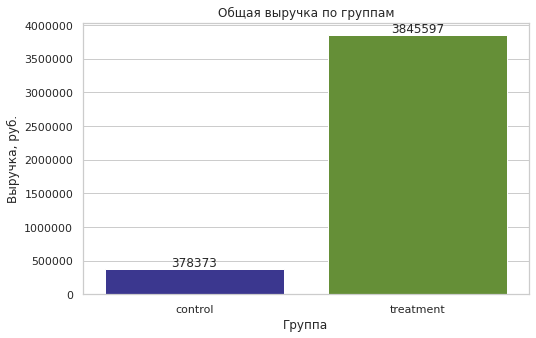

In [72]:
total_rev_control = results.loc[results['group'] == 'control', 'revenue'].values[0]
total_rev_treatment = results.loc[results['group'] == 'treatment', 'revenue'].values[0]
diff_revenue = total_rev_treatment - total_rev_control
print(f'Общая выручка контрольной группы: {total_rev_control:.2f} руб.')
print(f'Общая выручка тестовой группы: {total_rev_treatment:.2f} руб.')
print(f'Разница тестовая - контрольная: {diff_revenue:.2f} руб.')
print(f'Относительный прирост: {(diff_revenue / total_rev_control) * 100:.1f}%')

plt.figure(figsize=(8, 5))
barplot = sns.barplot(data=results, x='group', y='revenue', palette=['#2E289E', '#669E28'])
plt.title('Общая выручка по группам')
plt.xlabel('Группа')
plt.ylabel('Выручка, руб.')
plt.ticklabel_format(style='plain', axis='y')
for p in barplot.patches:
    barplot.annotate(f'{p.get_height():.0f}', 
                     (p.get_x() + p.get_width() / 2, p.get_height()), 
                     ha = 'center', va = 'bottom')
plt.show()

Общая выручка от пользователей TikTok выросла на 3 467 224 рубля, или на 916%. Это подтверждает, что эксперимент не только увеличил конверсию, но и принёс значительный дополнительный доход бизнесу. Бонус полностью окупился.

## Выводы по этапу 5

### Итоги A/B-теста бонуса на первую покупку

Эксперимент по предоставлению бонуса на первую покупку пользователям, привлечённым через **TikTok**, показал выраженный положительный эффект. Бонус существенно повысил вероятность первой покупки, увеличил выручку на пользователя и принёс дополнительную выручку маркетплейсу.

> **Вывод:** гипотеза о том, что финансовый стимул увеличит конверсию пользователей TikTok в первую покупку, **подтвердилась**.

### Результаты эксперимента

- **Конверсия в первую покупку** увеличилась с **1,06%** до **7,51%**. Статистическая значимость результата `p-value < 0.001` позволяет отвергнуть гипотезу об отсутствии эффекта. Рост конверсии с высокой вероятностью связан именно с предоставлением бонуса.
- **ARPU** вырос с **251 руб.** до **2 625 руб.**. Бутстрап-анализ показал, что 95% доверительный интервал разницы между группами не включает ноль. Следовательно, бонус статистически значимо увеличил выручку, приходящуюся на одного привлечённого пользователя.
- **ARPPU** увеличился с **23 648 руб.** до **34 960 руб.** Средняя разница между тестовой и контрольной группами составила **11 232,15 руб.**, а 95% доверительный интервал — **(368,03, 22 216,11) руб.** Поскольку интервал не включает `0`, различие статистически значимо. Однако результат следует интерпретировать осторожно - в контрольной группе было всего **16 покупателей**.
- **Средний чек (AOV)** вырос с **15 765 руб.** в контрольной группе до **16 647 руб.** в тестовой. Средняя разница составила **869,72 руб.**, 95% доверительный интервал - **(-5 636,87, 6 873,15) руб.** Поскольку интервал включает `0`, статистически значимых различий среднего чека между группами не выявлено.
- **Общая выручка** от пользователей TikTok увеличилась с **378 тыс. руб.** до **3,8 млн руб.**, или на **916%**. Барьерная метрика не выявила негативного влияния бонуса на финансовый результат: тестовая механика принесла бизнесу дополнительную выручку.

### Рекомендации

1. **Масштабировать бонусную механику.**  
   Тест показал положительный и статистически значимый эффект на конверсию и ARPU. Рекомендуется внедрить бонус для новых пользователей TikTok на постоянной основе либо провести следующий тест с большей продолжительностью и несколькими вариантами размера бонуса.
2. **Изучить сегмент крупных покупателей.**  
   В тестовой группе были зафиксированы крупные заказы - до **180 тыс. руб.** Необходимо изучить профиль этих пользователей: регион, возраст, товары, категории и дальнейшее поведение. Для такого сегмента можно разработать отдельные персонализированные предложения.
3. **Проверить долгосрочный эффект.**  
   Следующий эксперимент стоит проводить с более длинным горизонтом наблюдения, чтобы оценить влияние бонуса не только на первую покупку, но и на повторные заказы, retention и долгосрочный LTV.

### Ограничения эксперимента

- **Не рассчитывалась статистическая мощность до запуска.**  
  Эксперимент проводился в условиях срочности, поэтому заранее не были определены минимальный размер выборки и минимальный детектируемый эффект (`MDE`). При меньшем эффекте существовал риск не обнаружить реальные различия между группами.
- **Малая выборка покупателей в контрольной группе.**  
  В контрольной группе покупку совершили только **16 пользователей из 1 503**. Поэтому оценки **ARPPU** и **AOV** в контроле имеют высокую неопределённость, а результаты по этим метрикам нужно трактовать с осторожностью.
- **Короткий горизонт наблюдения - 3 недели.**  
  Тест измеряет эффект на первую покупку и выручку в краткосрочном периоде. Он не позволяет оценить, будут ли пользователи возвращаться и совершать повторные покупки после получения бонуса.

### Финальный вывод
Бонус на первую покупку для пользователей TikTok показал **сильный положительный эффект**: конверсия в первую покупку, ARPU и ARPPU статистически значимо выросли. Для среднего чека статистически значимых различий не обнаружено, поэтому нет оснований утверждать, что бонус изменил размер заказа. Механику целесообразно масштабировать, но перед полным запуском стоит проверить устойчивость эффекта на более длительном периоде и большей выборке.